# ENGE707 Kaggle Competition - Assessment 3

## Task 1 : Dataset Exploration and Understanding

In [1]:
"""01 Data Exploration: Dataset Structure

Inspects the structure of the training and test data before any modelling.
Each check prints a PASS/FAIL result so the output can be used as evidence in the report (Task 1.2).

Paths are found automatically through preprocessing.py. Run:  python 01_data_structure.py
"""

# %% Configuration
# All paths are defined once here. Adjust `DATA_DIR` to wherever the Kaggle files are stored.
from pathlib import Path
from collections import Counter

import pandas as pd
from PIL import Image

import preprocessing as pp                   # shared module: finds the project folder automatically
DATA_DIR = pp.DATA_DIR                       # the data/ folder in the project
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
SAMPLE_SUB_CSV = DATA_DIR / "sample_submission.csv"
OUTPUT_DIR = pp.OUTPUT_DIR                   # the outputs/ folder in the project
OUTPUT_DIR.mkdir(exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
EXPECTED_CLASSES = {"CatEye", "DogEye", "CatFace", "DogFace",
                    "CatMouth", "DogMouth", "CatNose", "DogNose"}

print(f"Working directory: {Path.cwd()}")
missing = []
for p in [TRAIN_DIR, TEST_DIR, TRAIN_CSV, SAMPLE_SUB_CSV]:
    print(f"{'found  ' if p.exists() else 'MISSING'}  {p.resolve()}")
    if not p.exists():
        missing.append(p)
if missing:
    raise SystemExit("Some paths are missing. Set DATA_DIR (and TRAIN_CSV if the label file "
                     "has a different name) at the top of this script, then run it again.")

# %% 1. Load the CSV files
# `image_id` is read as text (`dtype=str`) so zero-padded IDs such as `00001` keep their leading zeros and match the filenames.
train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
sub_df = pd.read_csv(SAMPLE_SUB_CSV, dtype={"image_id": str})

print("train_labels.csv")
print(f"  shape: {train_df.shape}, columns: {list(train_df.columns)}")
print(train_df.head())

print("sample_submission.csv")
print(f"  shape: {sub_df.shape}, columns: {list(sub_df.columns)}")
print(sub_df.head())

# %% 2. Folder inventory
# Counts every file in each folder and groups them by extension, so unexpected files (hidden system files, non-images) are visible.
def inventory(folder):
    # Searches subfolders too, since Kaggle zips often unpack as train/train/...
    files = [f for f in folder.rglob("*") if f.is_file()]
    images = [f for f in files if f.suffix.lower() in IMAGE_EXTENSIONS]
    other = [f for f in files if f.suffix.lower() not in IMAGE_EXTENSIONS]
    subfolders = [d for d in folder.rglob("*") if d.is_dir()]
    return files, images, other, subfolders

folder_info = {}
for name, folder in [("train", TRAIN_DIR), ("test", TEST_DIR)]:
    if not folder.is_dir():
        raise SystemExit(f"Folder not found: {folder.resolve()}\n"
                         f"Set DATA_DIR at the top of this script to the folder containing train/ and test/.")
    files, images, other, subfolders = inventory(folder)
    folder_info[name] = images
    print(f"[{name}/]  ({folder.resolve()})")
    print(f"  total files:       {len(files)}")
    print(f"  image files:       {len(images)}")
    print(f"  extensions:        {dict(Counter(f.suffix.lower() for f in files))}")
    print(f"  non-image files:   {len(other)} {[f.name for f in other[:10]]}")
    print(f"  subfolders:        {len(subfolders)} {[str(d.relative_to(folder)) for d in subfolders[:10]]}")
    print(f"  example files:     {sorted(str(f.relative_to(folder)) for f in images)[:5]}")
    if not images:
        raise SystemExit(f"No image files found in {folder.resolve()}. "
                         f"Check DATA_DIR and the file extensions listed above.")

# %% 3. Training labels against training images
# Matches filenames (without extension) to `image_id` in both directions.
train_files = {f.stem: f for f in folder_info["train"]}
label_ids = set(train_df["image_id"])

labels_without_image = label_ids - set(train_files)
images_without_label = set(train_files) - label_ids
duplicate_ids = train_df["image_id"][train_df["image_id"].duplicated()].tolist()
unexpected_classes = set(train_df["class"].unique()) - EXPECTED_CLASSES

def check(description, passed, detail=""):
    print(f"[{'PASS' if passed else 'FAIL'}] {description} {detail}")

check("Row count matches image count:", len(train_df) == len(train_files),
      f"({len(train_df)} rows, {len(train_files)} images)")
check("Every label has a matching image:", not labels_without_image,
      f"({len(labels_without_image)} missing) {sorted(labels_without_image)[:5]}")
check("Every image has a label:", not images_without_label,
      f"({len(images_without_label)} unlabelled) {sorted(images_without_label)[:5]}")
check("All image_id values are unique:", not duplicate_ids,
      f"({len(duplicate_ids)} duplicates) {duplicate_ids[:5]}")
check("All class values are one of the eight expected classes:", not unexpected_classes,
      f"{sorted(unexpected_classes)}")
check("No missing values in train_labels.csv:", train_df.isna().sum().sum() == 0)

print("\nClasses found:", sorted(train_df["class"].unique()))

# %% 4. Test images against the sample submission
# Also inspects what the `class` column of the sample submission contains, which settles the exact label spelling expected by the grader (for example `DogEye` vs `DogEyes`).
test_files = {f.stem: f for f in folder_info["test"]}
sub_ids = set(sub_df["image_id"])

# IDs are compared by numeric value, because the submission may write "1" where the file is "00001.jpg"
def as_number(i):
    return int(i) if str(i).strip().isdigit() else str(i)

sub_nums = {as_number(i) for i in sub_ids}
file_nums = {as_number(i) for i in test_files}
padding_differs = bool(sub_ids - set(test_files)) and sub_nums == file_nums

check("Submission row count matches test image count:", len(sub_df) == len(test_files),
      f"({len(sub_df)} rows, {len(test_files)} images)")
check("Every submission ID has a test image:", not (sub_nums - file_nums),
      f"({len(sub_nums - file_nums)} missing) {sorted(map(str, sub_nums - file_nums))[:5]}")
check("Every test image appears in the submission:", not (file_nums - sub_nums),
      f"({len(file_nums - sub_nums)} absent) {sorted(map(str, file_nums - sub_nums))[:5]}")
if padding_differs:
    print("[NOTE] Submission IDs are not zero-padded (e.g. '1') while test files are (e.g. '00001.jpg'). "
          "They match by numeric value; the submission must keep the sample's ID format.")
check("Submission IDs are unique:", not sub_df["image_id"].duplicated().any())

print("\nValues in sample_submission 'class' column:")
print(sub_df["class"].value_counts())
print("\nValues NOT in the training label set:",
      sorted(set(sub_df["class"].astype(str)) - EXPECTED_CLASSES))

# %% #ID ranges and overlap
# Both sets may number from `00001`, so the same ID can refer to different images in `train/` and `test/`. Paths must always include the folder.
def id_summary(ids, name):
    nums = sorted(int(i) for i in ids)
    gaps = (nums[-1] - nums[0] + 1) - len(nums)
    print(f"{name}: min {nums[0]}, max {nums[-1]}, count {len(nums)}, gaps in range {gaps}, "
          f"ID string lengths {sorted({len(i) for i in ids})}")

id_summary(label_ids, "train")
id_summary(sub_ids, "test ")
overlap = {as_number(i) for i in label_ids} & sub_nums
print(f"ID numbers shared between train and test: {len(overlap)} (different images, same ID number)")

# %% 5. Basic image properties
# Reads only the image header (fast), recording format, colour mode and dimensions for every image.
# Files that fail to open are recorded rather than stopping the loop. The table is saved for reuse in the data quality section.
def image_properties(files, split):
    records = []
    for image_id, path in files.items():
        try:
            with Image.open(path) as img:
                records.append({"split": split, "image_id": image_id, "file": path.name,
                                "format": img.format, "mode": img.mode,
                                "width": img.width, "height": img.height, "error": None})
        except Exception as e:
            records.append({"split": split, "image_id": image_id, "file": path.name,
                            "format": None, "mode": None, "width": None, "height": None,
                            "error": type(e).__name__})
    return records

props = pd.DataFrame(image_properties(train_files, "train") + image_properties(test_files, "test"))
props.to_csv(OUTPUT_DIR / "image_properties.csv", index=False)

for split, g in props.groupby("split"):
    print(f"[{split}]  images: {len(g)}, failed to open: {g['error'].notna().sum()}")
    print(f"  formats: {g['format'].value_counts(dropna=False).to_dict()}")
    print(f"  modes:   {g['mode'].value_counts(dropna=False).to_dict()}")
    print(f"  width  min/median/max: {g['width'].min()} / {g['width'].median()} / {g['width'].max()}")
    print(f"  height min/median/max: {g['height'].min()} / {g['height'].median()} / {g['height'].max()}")
    print(f"  distinct (width, height) sizes: {g.groupby(['width', 'height']).ngroups}")

# %% 6. Summary table for the report

def describe(split, n_csv_rows, labelled, use):
    g = props[props["split"] == split]
    return {"Folder": f"{split}/",
            "Images": len(g),
            "CSV rows": n_csv_rows,
            "Format(s)": ", ".join(sorted(g["format"].dropna().unique())),
            "Colour mode(s)": ", ".join(sorted(g["mode"].dropna().unique())),
            "Size range (W x H)": f"{int(g['width'].min())}x{int(g['height'].min())} to "
                                  f"{int(g['width'].max())}x{int(g['height'].max())}",
            "Labelled": labelled,
            "Used for": use}

summary = pd.DataFrame([
    describe("train", len(train_df), "Yes (train_labels.csv)", "Training and validation"),
    describe("test", len(sub_df), "No", "Kaggle predictions only"),
])
summary.to_csv(OUTPUT_DIR / "dataset_structure_summary.csv", index=False)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
print(summary.to_string(index=False))

Working directory: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/src
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/train
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/test
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/train_labels.csv
found    /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/data/sample_submission.csv
train_labels.csv
  shape: (63660, 2), columns: ['image_id', 'class']
  image_id     class
0    00001    DogEye
1    00002  DogMouth
2    00003   DogFace
3    00004   DogNose
4    00005   DogNose
sample_submission.csv
  shape: (29443, 2), columns: ['image_id', 'class']
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  

### Class Distribution

Rows in train_labels.csv: 63660
Labels with a matching image: 63660 (dropped 0)

Images per class
          Images  Share (%)
class                      
CatEye     13884       21.8
DogEye     11580       18.2
CatFace     6942       10.9
DogFace     5790        9.1
CatMouth    6942       10.9
DogMouth    5790        9.1
CatNose     6942       10.9
DogNose     5790        9.1
Total      63660      100.0

Largest class(es):  CatEye (13884)
Smallest class(es): DogFace, DogMouth, DogNose (5790)
Imbalance ratio (largest / smallest): 2.40

By species:
  Cat     34710  (54.5%)
  Dog     28950  (45.5%)

By part:
  Eye     25464  (40.0%)
  Mouth   12732  (20.0%)
  Face    12732  (20.0%)
  Nose    12732  (20.0%)

Source-photo pattern check
  Cat: Face=6942, Mouth=6942, Nose=6942, Eye=13884  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True
  Dog: Face=5790, Mouth=5790, Nose=5790, Eye=11580  ->  Face=Mouth=Nose: True, Eye = 2 x Face: True

Saved chart to /Users/christian/Uni_Files/2026/Semester 2/D

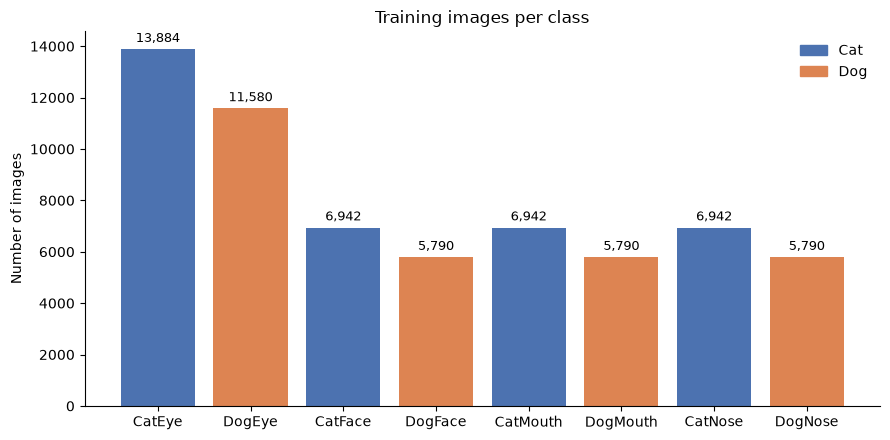

In [2]:
"""02 Data Exploration: Class Distribution

Counts the images in each class and checks how balanced the dataset is (report Tasks 1.3 and 1.4).
Counts are taken from train_labels.csv and confirmed against the image files that actually exist,
so the reported numbers reflect usable training images.

Paths are found automatically through preprocessing.py. Run:  python 02_class_distribution.py
Requires: pandas, matplotlib
"""

# %% Configuration
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

import preprocessing as pp                   # shared module: finds the project folder automatically
DATA_DIR = pp.DATA_DIR                       # the data/ folder in the project
TRAIN_DIR = DATA_DIR / "train"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
OUTPUT_DIR = pp.OUTPUT_DIR                   # the outputs/ folder in the project
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CLASS_ORDER = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]

train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
print(f"Rows in {TRAIN_CSV.name}: {len(train_df)}")

# %% 1. Keep only labels whose image file exists
# If 01_data_structure.py reported every label matched an image, nothing is dropped here.
existing_ids = {f.stem for f in TRAIN_DIR.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS}
train_df["has_image"] = train_df["image_id"].isin(existing_ids)
print(f"Labels with a matching image: {train_df['has_image'].sum()} "
      f"(dropped {(~train_df['has_image']).sum()})")
df = train_df[train_df["has_image"]].copy()

# %% 2. Images per class
counts = df["class"].value_counts().reindex(CLASS_ORDER)
table = pd.DataFrame({"Images": counts, "Share (%)": (counts / counts.sum() * 100).round(1)})
table.loc["Total"] = [counts.sum(), 100.0]
table["Images"] = table["Images"].astype(int)
print("\nImages per class")
print(table.to_string())
table.to_csv(OUTPUT_DIR / "class_counts.csv")

# %% 3. Balance measures
# The eight classes combine species (Cat/Dog) and facial part (Eye/Face/Mouth/Nose),
# so each factor is summarised separately as well.
df["species"] = df["class"].str[:3]
df["part"] = df["class"].str[3:]

ratio = counts.max() / counts.min()
# Lists every class sharing the max or min, since several classes may tie.
print(f"\nLargest class(es):  {', '.join(counts[counts == counts.max()].index)} ({counts.max()})")
print(f"Smallest class(es): {', '.join(counts[counts == counts.min()].index)} ({counts.min()})")
print(f"Imbalance ratio (largest / smallest): {ratio:.2f}")

for factor in ["species", "part"]:
    s = df[factor].value_counts()
    print(f"\nBy {factor}:")
    for k, v in s.items():
        print(f"  {k:<6} {v:>6}  ({v / len(df) * 100:.1f}%)")

# %% 4. Check the source-photo pattern
# Hypothesis: each source photo yields one face, one mouth, one nose and two eye crops.
# If true, within each species Face = Mouth = Nose and Eye = 2 x Face.
print("\nSource-photo pattern check")
for sp in ["Cat", "Dog"]:
    face, mouth, nose, eye = (counts[f"{sp}{p}"] for p in ["Face", "Mouth", "Nose", "Eye"])
    print(f"  {sp}: Face={face}, Mouth={mouth}, Nose={nose}, Eye={eye}  ->  "
          f"Face=Mouth=Nose: {face == mouth == nose}, Eye = 2 x Face: {eye == 2 * face}")

# %% 5. Bar chart for the report
fig, ax = plt.subplots(figsize=(9, 4.5))
colours = ["#4C72B0" if c.startswith("Cat") else "#DD8452" for c in CLASS_ORDER]
bars = ax.bar(CLASS_ORDER, counts.values, color=colours)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3, fontsize=9)
ax.set_ylabel("Number of images")
ax.set_title("Training images per class")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#4C72B0"),
                   plt.Rectangle((0, 0), 1, 1, color="#DD8452")],
          labels=["Cat", "Dog"], frameon=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "class_distribution.png", dpi=200)
print(f"\nSaved chart to {FIG_DIR / 'class_distribution.png'}")
plt.show()

### Data Quality Issues 

Images to check: 93103 (train 63660, test 29443)
  5000/93103 images  (2s)
  10000/93103 images  (5s)
  15000/93103 images  (7s)
  20000/93103 images  (9s)
  25000/93103 images  (11s)
  30000/93103 images  (13s)
  35000/93103 images  (15s)
  40000/93103 images  (18s)
  45000/93103 images  (20s)
  50000/93103 images  (22s)
  55000/93103 images  (24s)
  60000/93103 images  (26s)
  65000/93103 images  (28s)
  70000/93103 images  (30s)
  75000/93103 images  (32s)
  80000/93103 images  (34s)
  85000/93103 images  (37s)
  90000/93103 images  (39s)
  93103/93103 images  (40s)

1. CORRUPTED FILES: 0 of 93103 images could not be fully decoded

2. IMAGE SIZES
  [test] distinct sizes: 7786, width 8 to 1832 (median 82), height 9 to 1978 (median 80), non-square: 67.2%
    most common sizes: 40x40 (503), 50x50 (402), 80x80 (370), 30x30 (349), 60x60 (343)
    colour modes: {'RGB': 29443}
  [train] distinct sizes: 7861, width 4 to 2219 (median 84), height 4 to 2219 (median 80), non-square: 34.5%
    m

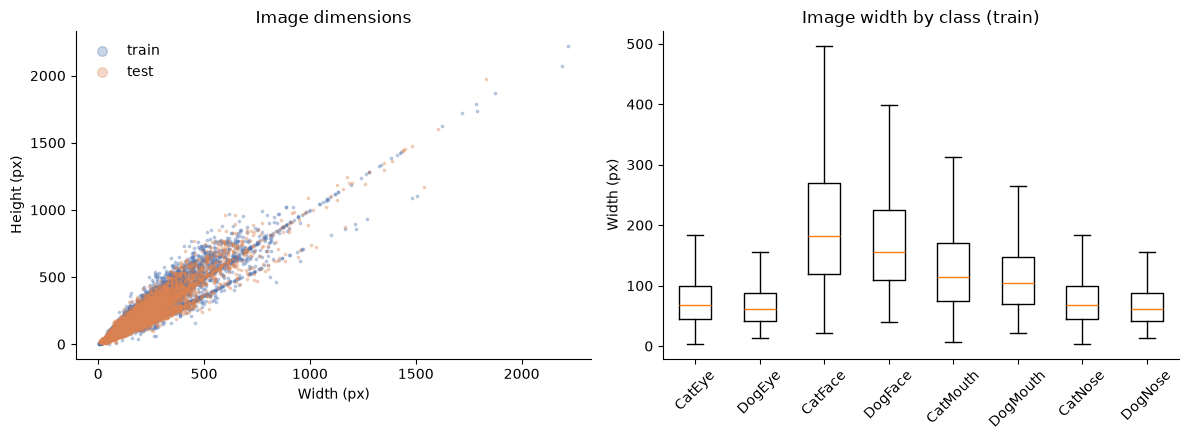

  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/smallest_images.png


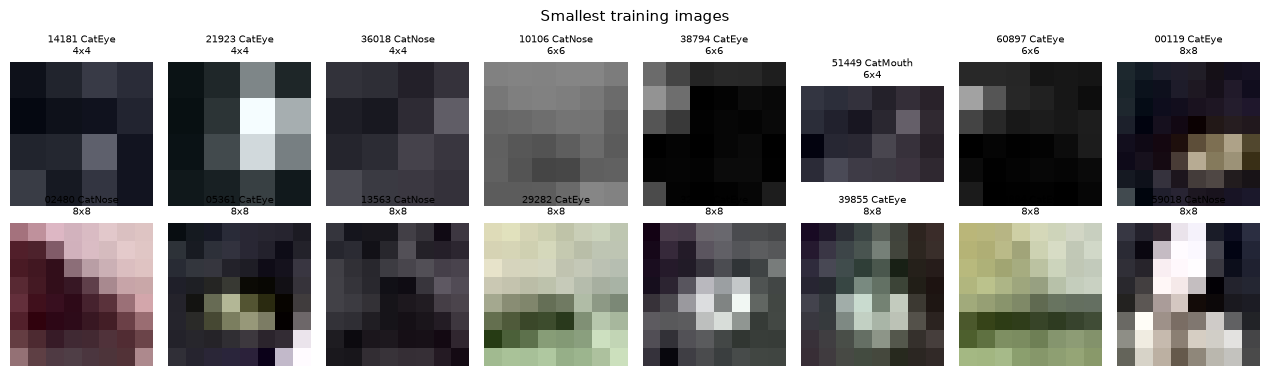


3. BLUR: sharpness median 197.7, bottom-1% cut-off 3.1; 932 images flagged as blurriest
  Blurriest-1% rate per class (train). An uneven spread suggests some classes are naturally softer:
  CatEye 1.4%, DogEye 2.0%, CatFace 0.0%, DogFace 0.0%, CatMouth 0.5%, DogMouth 0.0%, CatNose 2.6%, DogNose 1.2%
  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/sharpness_distribution.png


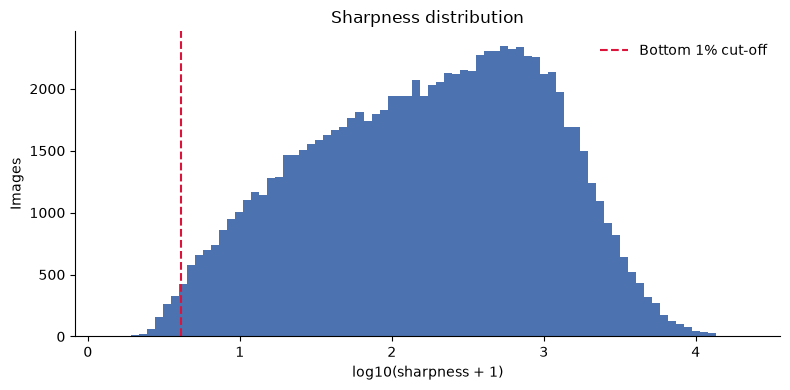

  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/blurriest_images.png


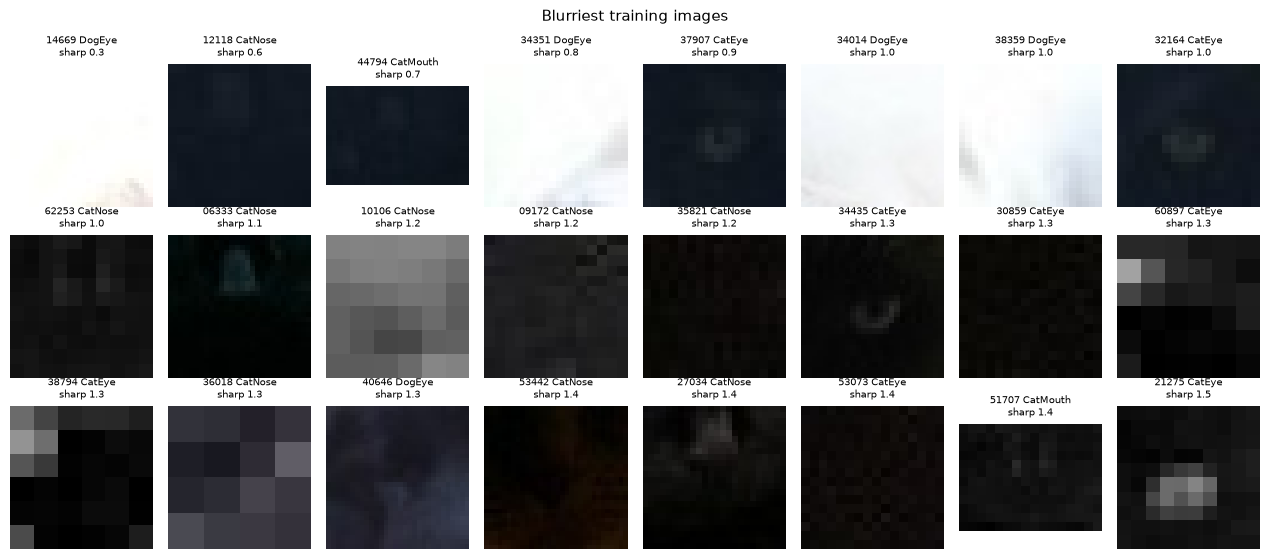


4. EXPOSURE: very dark 531, very bright 80, near-uniform 141
  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/extreme_exposure.png


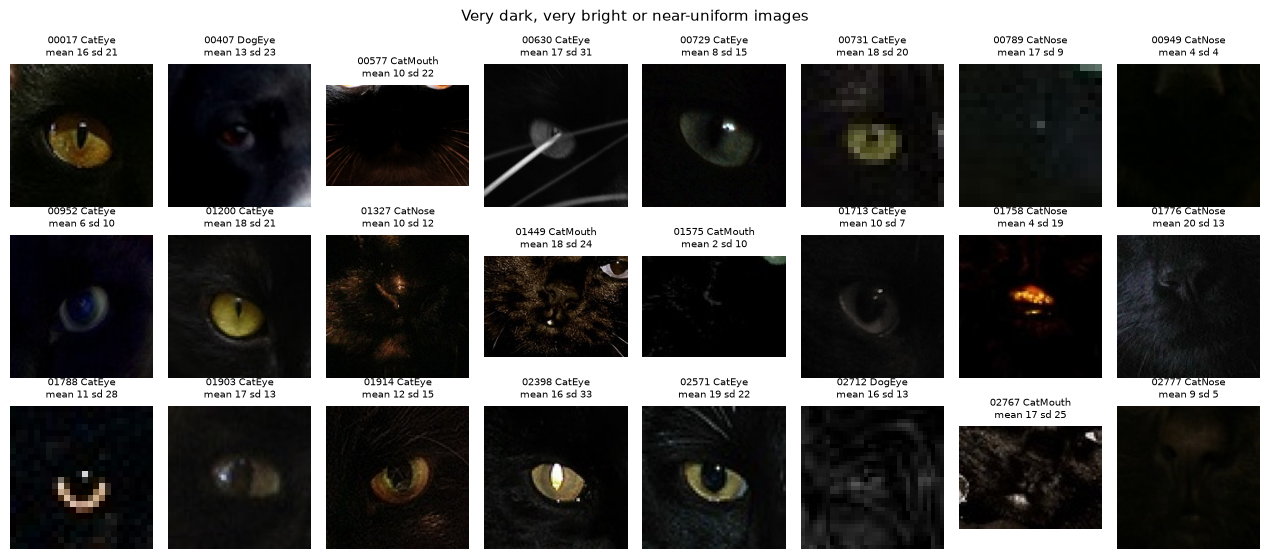


5. DUPLICATES
  Exact duplicates within train: 15 groups covering 30 images
    groups whose copies have DIFFERENT labels: 0
    train images that also appear in test: 0 (0 distinct pictures)
  Near duplicates within train: 40 groups covering 80 images
    groups whose copies have DIFFERENT labels: 0
    train images that also appear in test: 2 (2 distinct pictures)
  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/near_duplicates.png


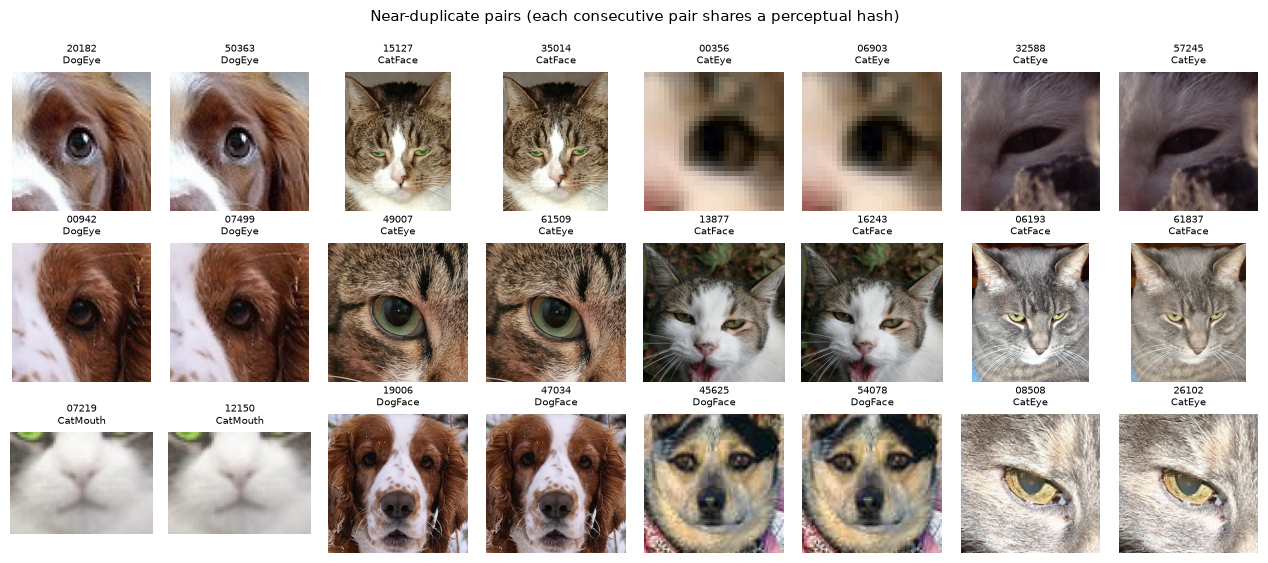


6. CLASS BOUNDARIES: review the per-class grid for ambiguous examples
  saved /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/class_samples_review.png


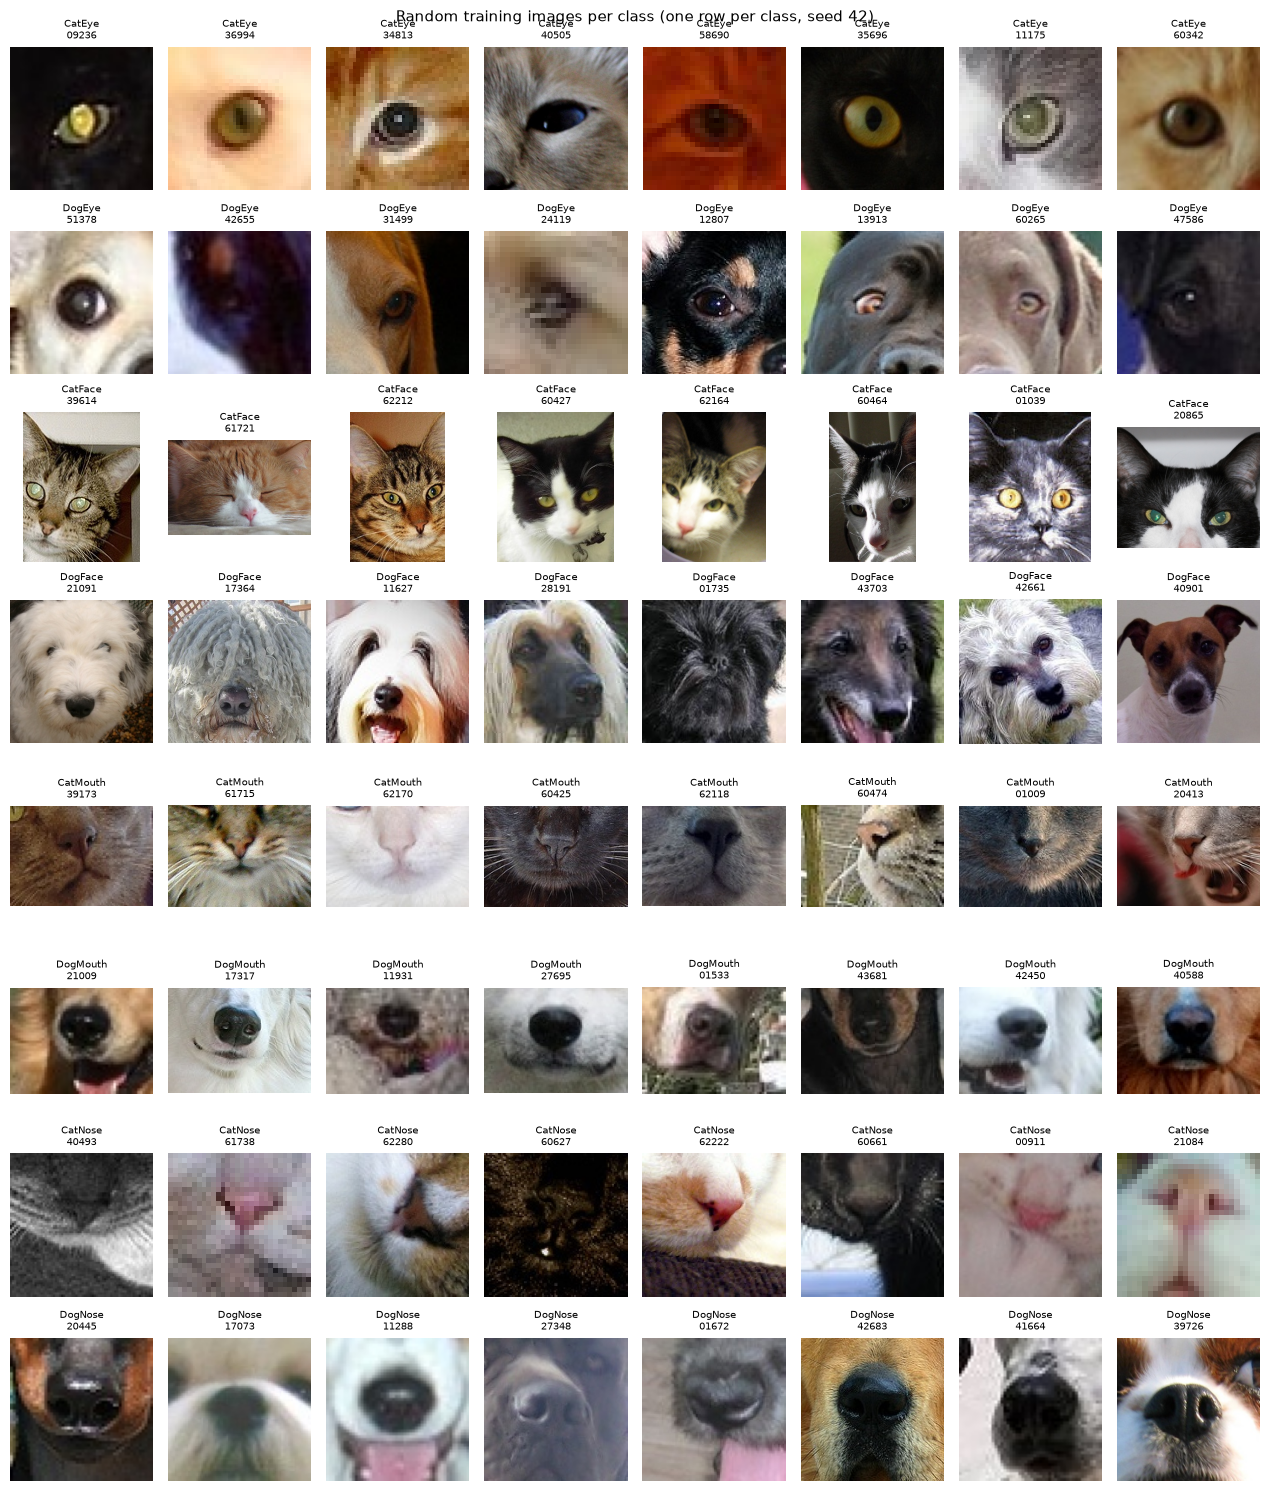


SUMMARY
                                        Check         Result                          Note
                              Corrupted files              0    Could not be fully decoded
                 Distinct image sizes (train)           7861            Width 4 to 2219 px
                     Blurriest images flagged            932        Bottom 1% of sharpness
            Very dark / bright / near-uniform 531 / 80 / 141 Mean < 20, mean > 235, sd < 8
               Exact duplicate groups (train)             15          Identical file bytes
                Near-duplicate groups (train)             40     Identical perceptual hash
Near-duplicate groups with conflicting labels              0 Same picture, different class
           Train pictures also in test (near)              2   Possible train/test overlap


In [3]:
"""03 Data Exploration: Data Quality

Checks the training and test images for the data quality issues listed in the brief (report Task 1.6):
  1. Corrupted files        every image is fully decoded, not just its header
  2. Inconsistent sizes     width, height and aspect ratio distributions, per class
  3. Blurry images          sharpness score (variance of the Laplacian)
  4. Blank or extreme images very dark, very bright or near-uniform images
  5. Duplicate images       exact duplicates (file hash) and near duplicates (perceptual hash),
                            within train, across classes, and between train and test
  6. Unclear class boundaries  visual grids of the most suspicious images for manual review

All per-image measurements are saved to outputs/quality_metrics.csv, and figures go to outputs/figures/.
On the full dataset the measurement pass takes a few minutes; progress is printed as it runs.

Paths are found automatically through preprocessing.py. Run:  python 03_data_quality.py
Requires: pandas, numpy, matplotlib, pillow
"""

# %% Configuration
import hashlib
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import preprocessing as pp                   # shared module: finds the project folder automatically
DATA_DIR = pp.DATA_DIR                       # the data/ folder in the project
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"
TRAIN_CSV = DATA_DIR / "train_labels.csv"
OUTPUT_DIR = pp.OUTPUT_DIR                   # the outputs/ folder in the project
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}
CLASS_ORDER = ["CatEye", "DogEye", "CatFace", "DogFace", "CatMouth", "DogMouth", "CatNose", "DogNose"]

SHARPNESS_SIZE = 128     # images are resized to this before scoring sharpness, so scores are comparable
BLUR_PERCENTILE = 1      # the blurriest 1% are flagged for review (a relative threshold, not an absolute one)
DARK_THRESHOLD = 20      # mean brightness (0 to 255) below this counts as very dark
BRIGHT_THRESHOLD = 235   # mean brightness above this counts as very bright
LOW_CONTRAST_STD = 8     # pixel standard deviation below this counts as near-uniform

train_df = pd.read_csv(TRAIN_CSV, dtype={"image_id": str})
labels = dict(zip(train_df["image_id"], train_df["class"]))

def find_images(folder):
    return sorted(f for f in folder.rglob("*") if f.suffix.lower() in IMAGE_EXTENSIONS)

files = [("train", f) for f in find_images(TRAIN_DIR)] + [("test", f) for f in find_images(TEST_DIR)]
print(f"Images to check: {len(files)} "
      f"(train {sum(s == 'train' for s, _ in files)}, test {sum(s == 'test' for s, _ in files)})")

# %% Measurement pass
# One pass over every image computes all the measurements, so each file is only read once.

LAPLACIAN_STEPS = [(-1, 0), (1, 0), (0, -1), (0, 1)]

def laplacian_variance(grey):
    """Variance of the 4-neighbour Laplacian. Low values mean few sharp edges, i.e. blur."""
    g = grey.astype(np.float32)
    lap = -4 * g[1:-1, 1:-1]
    for dy, dx in LAPLACIAN_STEPS:
        lap += g[1 + dy:g.shape[0] - 1 + dy, 1 + dx:g.shape[1] - 1 + dx]
    return float(lap.var())

def dhash(img, size=8):
    """Difference hash: a 64-bit fingerprint that stays the same when an image is resized,
    recompressed or slightly altered, so matching hashes indicate near-duplicate images."""
    small = np.asarray(img.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).flatten()
    return "".join("1" if b else "0" for b in bits)

records = []
start = time.time()
for i, (split, path) in enumerate(files, 1):
    rec = {"split": split, "image_id": path.stem, "path": str(path),
           "label": labels.get(path.stem) if split == "train" else None, "error": None}
    try:
        raw = path.read_bytes()
        rec["md5"] = hashlib.md5(raw).hexdigest()
        rec["file_kb"] = len(raw) / 1024
        with Image.open(path) as img:
            img.load()                                   # forces a full decode, which exposes truncated files
            rec.update(width=img.width, height=img.height, mode=img.mode)
            rgb = img.convert("RGB")
        grey = np.asarray(rgb.convert("L"), dtype=np.float32)
        rec["brightness"] = float(grey.mean())
        rec["contrast"] = float(grey.std())
        sharp_grey = np.asarray(rgb.convert("L").resize((SHARPNESS_SIZE, SHARPNESS_SIZE)))
        rec["sharpness"] = laplacian_variance(sharp_grey)
        rec["dhash"] = dhash(rgb)
    except Exception as e:
        rec["error"] = f"{type(e).__name__}: {e}"
    records.append(rec)
    if i % 5000 == 0 or i == len(files):
        print(f"  {i}/{len(files)} images  ({time.time() - start:.0f}s)")

q = pd.DataFrame(records)
for col in ["width", "height"]:
    q[col] = q[col].astype("Int64")      # whole numbers even when a corrupted row leaves a gap
q["aspect"] = q["width"] / q["height"]
q.to_csv(OUTPUT_DIR / "quality_metrics.csv", index=False)
ok = q[q["error"].isna()].copy()
train_ok = ok[ok["split"] == "train"]

# Helper for image grids used throughout
def show_grid(rows, title, filename, n_cols=8, caption=None):
    rows = list(rows.itertuples()) if isinstance(rows, pd.DataFrame) else list(rows)
    if not rows:
        print(f"  (no images to show for: {title})")
        return
    n_rows = int(np.ceil(len(rows) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.6, n_rows * 1.9), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, rows):
        with Image.open(r.path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(caption(r) if caption else f"{r.image_id}\n{r.label or r.split}",
                     fontsize=7)
    fig.suptitle(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    print(f"  saved {FIG_DIR / filename}")
    plt.show()

# %% 1. Corrupted files
errors = q[q["error"].notna()]
print(f"\n1. CORRUPTED FILES: {len(errors)} of {len(q)} images could not be fully decoded")
if len(errors):
    print(errors[["split", "image_id", "error"]].to_string(index=False))

# %% 2. Image sizes and aspect ratios
print("\n2. IMAGE SIZES")
for split, g in ok.groupby("split"):
    print(f"  [{split}] distinct sizes: {g.groupby(['width', 'height']).ngroups}, "
          f"width {g['width'].min()} to {g['width'].max()} (median {g['width'].median():.0f}), "
          f"height {g['height'].min()} to {g['height'].max()} (median {g['height'].median():.0f}), "
          f"non-square: {(g['width'] != g['height']).mean() * 100:.1f}%")
    top = g.groupby(["width", "height"]).size().sort_values(ascending=False).head(5)
    print("    most common sizes: " + ", ".join(f"{w}x{h} ({n})" for (w, h), n in top.items()))
    print(f"    colour modes: {g['mode'].value_counts().to_dict()}")

print("\n  Median size per class (train). Large differences mean size alone could reveal the class:")
by_class = train_ok.groupby("label")[["width", "height", "aspect"]].median().reindex(CLASS_ORDER)
print(by_class.astype(float).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for split, colour in [("train", "#4C72B0"), ("test", "#DD8452")]:
    g = ok[ok["split"] == split]
    axes[0].scatter(g["width"], g["height"], s=3, alpha=0.3, color=colour, label=split)
axes[0].set_xlabel("Width (px)"); axes[0].set_ylabel("Height (px)")
axes[0].set_title("Image dimensions"); axes[0].legend(markerscale=4, frameon=False)
axes[1].boxplot([train_ok.loc[train_ok["label"] == c, "width"] for c in CLASS_ORDER],
                showfliers=False)
axes[1].set_xticks(range(1, len(CLASS_ORDER) + 1), CLASS_ORDER, rotation=45)
axes[1].set_title("Image width by class (train)"); axes[1].set_xlabel(""); axes[1].set_ylabel("Width (px)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "image_sizes.png", dpi=200)
print(f"  saved {FIG_DIR / 'image_sizes.png'}")
plt.show()

show_grid(train_ok.nsmallest(16, "width"), "Smallest training images", "smallest_images.png",
          caption=lambda r: f"{r.image_id} {r.label}\n{r.width}x{r.height}")

# %% 3. Blurry images
blur_cut = ok["sharpness"].quantile(BLUR_PERCENTILE / 100)
ok["blurry"] = ok["sharpness"] <= blur_cut
print(f"\n3. BLUR: sharpness median {ok['sharpness'].median():.1f}, "
      f"bottom-{BLUR_PERCENTILE}% cut-off {blur_cut:.1f}; {ok['blurry'].sum()} images flagged as blurriest")
print("  Blurriest-1% rate per class (train). An uneven spread suggests some classes are naturally softer:")
rate = ok[ok["split"] == "train"].groupby("label")["blurry"].mean().reindex(CLASS_ORDER) * 100
print("  " + ", ".join(f"{c} {v:.1f}%" for c, v in rate.items()))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.log10(ok["sharpness"] + 1), bins=80, color="#4C72B0")
ax.axvline(np.log10(blur_cut + 1), color="crimson", ls="--", label=f"Bottom {BLUR_PERCENTILE}% cut-off")
ax.set_xlabel("log10(sharpness + 1)"); ax.set_ylabel("Images"); ax.set_title("Sharpness distribution")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIG_DIR / "sharpness_distribution.png", dpi=200)
print(f"  saved {FIG_DIR / 'sharpness_distribution.png'}")
plt.show()

show_grid(ok[ok["split"] == "train"].nsmallest(24, "sharpness"), "Blurriest training images",
          "blurriest_images.png",
          caption=lambda r: f"{r.image_id} {r.label}\nsharp {r.sharpness:.1f}")

# %% 4. Blank, very dark, very bright or near-uniform images
dark = ok[ok["brightness"] < DARK_THRESHOLD]
bright = ok[ok["brightness"] > BRIGHT_THRESHOLD]
flat = ok[ok["contrast"] < LOW_CONTRAST_STD]
print(f"\n4. EXPOSURE: very dark {len(dark)}, very bright {len(bright)}, near-uniform {len(flat)}")
extreme = pd.concat([dark, bright, flat]).drop_duplicates("path")
show_grid(extreme.head(24), "Very dark, very bright or near-uniform images", "extreme_exposure.png",
          caption=lambda r: f"{r.image_id} {r.label or r.split}\n"
                            f"mean {r.brightness:.0f} sd {r.contrast:.0f}")

# %% 5. Duplicates
# Exact duplicates share a file hash (byte-for-byte identical).
# Near duplicates share a perceptual hash (same picture after resizing or recompression).
print("\n5. DUPLICATES")

def duplicate_groups(df, key):
    groups = df[df.duplicated(key, keep=False)].groupby(key)
    return [g for _, g in groups]

for key, name in [("md5", "Exact"), ("dhash", "Near")]:
    tr_groups = duplicate_groups(train_ok, key)
    n_imgs = sum(len(g) for g in tr_groups)
    conflicting = [g for g in tr_groups if g["label"].nunique() > 1]
    cross = set(train_ok[key]) & set(ok.loc[ok["split"] == "test", key])
    print(f"  {name} duplicates within train: {len(tr_groups)} groups covering {n_imgs} images")
    print(f"    groups whose copies have DIFFERENT labels: {len(conflicting)}")
    print(f"    train images that also appear in test: "
          f"{train_ok[key].isin(cross).sum()} ({len(cross)} distinct pictures)")
    if conflicting:
        print("    examples of conflicting labels:")
        for g in conflicting[:5]:
            print("     ", ", ".join(f"{r.image_id}={r.label}" for r in g.itertuples()))

# The near-duplicate grid shows pairs side by side, label conflicts first, for visual confirmation.
near_groups = duplicate_groups(train_ok, "dhash")
near_groups.sort(key=lambda g: g["label"].nunique(), reverse=True)
pairs = pd.concat([g.head(2) for g in near_groups[:12]]) if near_groups else pd.DataFrame()
show_grid(pairs, "Near-duplicate pairs (each consecutive pair shares a perceptual hash)",
          "near_duplicates.png",
          caption=lambda r: f"{r.image_id}\n{r.label}")

# %% 6. Unclear class boundaries
# There is no automatic test for this. The grids below give material for visual judgement:
# random examples per class, to compare within-class variety with between-class differences.
# Look for crops that could reasonably belong to another class, e.g. tight face crops
# that resemble nose crops, or eye crops too small to show species.
print("\n6. CLASS BOUNDARIES: review the per-class grid for ambiguous examples")
rng_rows = []
for c in CLASS_ORDER:
    rng_rows.append(train_ok[train_ok["label"] == c].sample(n=min(8, (train_ok["label"] == c).sum()),
                                                             random_state=42))
show_grid(pd.concat(rng_rows), "Random training images per class (one row per class, seed 42)",
          "class_samples_review.png", n_cols=8,
          caption=lambda r: f"{r.label}\n{r.image_id}")

# %% Summary for the report
summary = pd.DataFrame([
    ["Corrupted files", len(errors), "Could not be fully decoded"],
    ["Distinct image sizes (train)", train_ok.groupby(["width", "height"]).ngroups,
     f"Width {train_ok['width'].min()} to {train_ok['width'].max()} px"],
    ["Blurriest images flagged", int(ok["blurry"].sum()), f"Bottom {BLUR_PERCENTILE}% of sharpness"],
    ["Very dark / bright / near-uniform", f"{len(dark)} / {len(bright)} / {len(flat)}",
     f"Mean < {DARK_THRESHOLD}, mean > {BRIGHT_THRESHOLD}, sd < {LOW_CONTRAST_STD}"],
    ["Exact duplicate groups (train)", len(duplicate_groups(train_ok, "md5")), "Identical file bytes"],
    ["Near-duplicate groups (train)", len(near_groups), "Identical perceptual hash"],
    ["Near-duplicate groups with conflicting labels", sum(g["label"].nunique() > 1 for g in near_groups),
     "Same picture, different class"],
    ["Train pictures also in test (near)", int(train_ok["dhash"].isin(ok.loc[ok["split"] == "test", "dhash"]).sum()),
     "Possible train/test overlap"],
], columns=["Check", "Result", "Note"])
summary.to_csv(OUTPUT_DIR / "quality_summary.csv", index=False)
pd.set_option("display.width", 200)
print("\nSUMMARY")
print(summary.to_string(index=False))

## Task 2: Data Preprocessing and Pipeline Preparation

### Data Preparation


Project folder: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment
Labelled training images: 63660
1. Excluded 190 images with shortest side under 16 px -> 63470 remain
2. Duplicate groups: 40 (covering 80 images, 0 with conflicting labels); removed 40 extra copies -> 63430 remain
3. Split: training 50744, validation 12686 (20.0% validation)

   Class proportions in each subset (stratification check):
          train_n  train_%  val_n  val_%  label_idx
label                                              
CatEye      11017    21.71   2754  21.71          0
DogEye       9253    18.23   2313  18.23          1
CatFace      5549    10.94   1387  10.93          2
DogFace      4628     9.12   1157   9.12          3
CatMouth     5527    10.89   1382  10.89          4
DogMouth     4631     9.13   1158   9.13          5
CatNose      5510    10.86   1378  10.86          6
DogNose      4629     9.12   1157   9.12          7

4. Test list: 29443 images, 

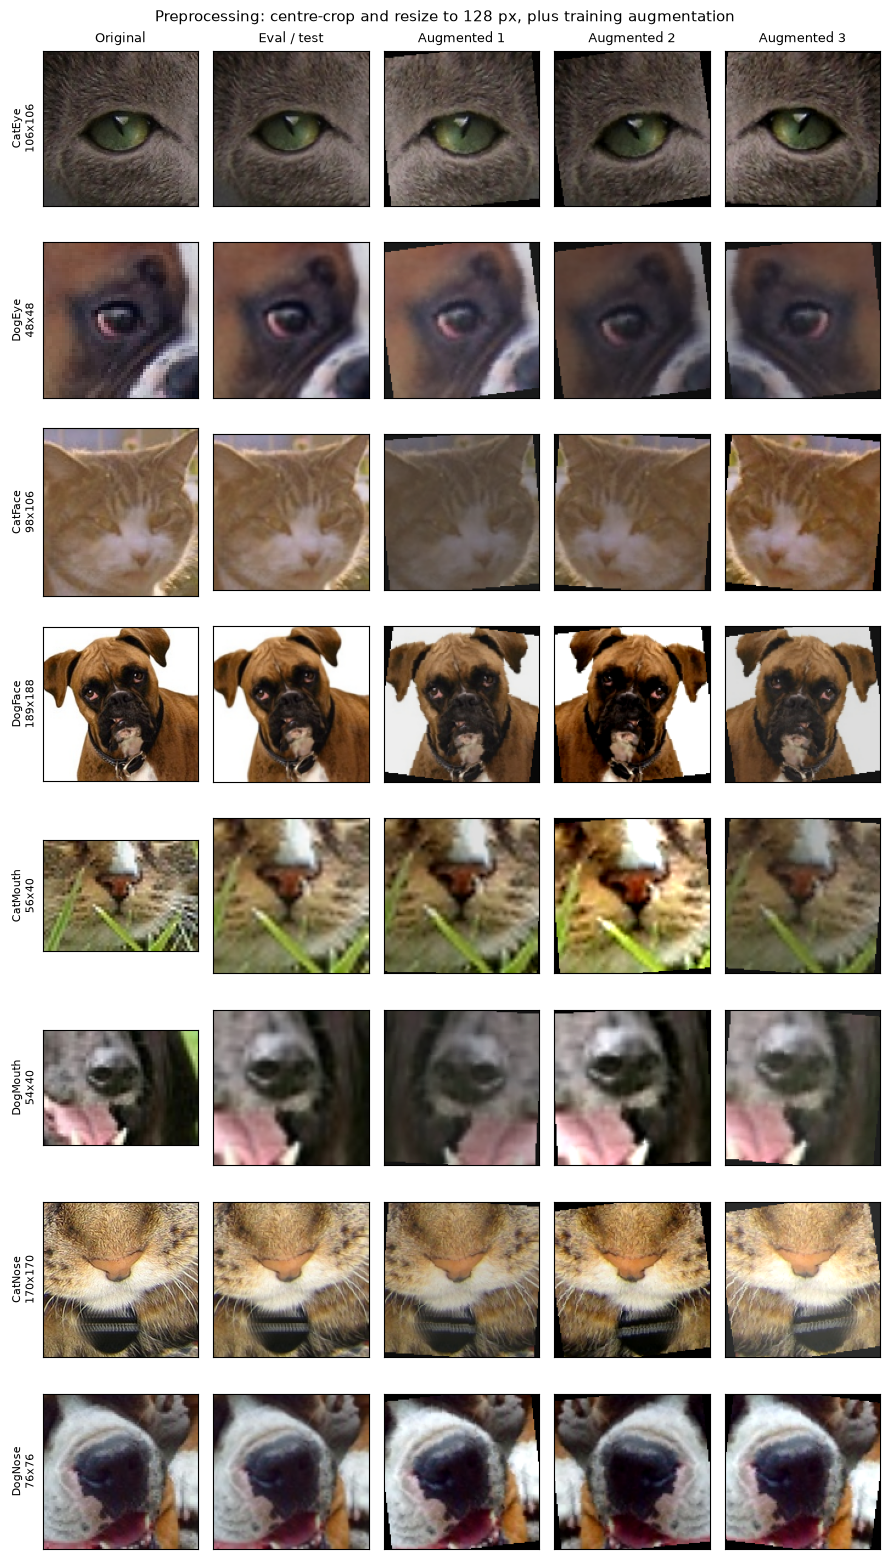

In [4]:
"""04 Data Preparation: Cleaning, Splitting and Pipeline Checks

Applies the data cleaning decisions from Task 1.6, creates the training/validation split,
and checks that the preprocessing pipeline from preprocessing.py works as intended (report Task 2).

Steps:
  1. Exclude training images whose shortest side is under 16 px
  2. Remove extra copies of duplicate images (exact and near duplicates), keeping one per group
  3. Stratified 80/20 split with a fixed seed, saved to outputs/splits/
  4. Build the test list in sample_submission.csv order
  5. Leakage checks between training, validation and test
  6. Pipeline checks: batch shapes, value ranges, label encoding, loading speed
  7. Figure showing the evaluation and training (augmented) transforms

Requires outputs/quality_metrics.csv from 03_data_quality.py.
Paths are found automatically by preprocessing.py, so this can run from the project folder or src/.
"""

# %% Setup
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader

import preprocessing as pp

print(f"Project folder: {pp.PROJECT_ROOT}")
pp.SPLIT_DIR.mkdir(parents=True, exist_ok=True)
pp.FIG_DIR.mkdir(parents=True, exist_ok=True)

labels = pd.read_csv(pp.TRAIN_CSV, dtype={"image_id": str})
quality = pd.read_csv(pp.QUALITY_CSV, dtype={"image_id": str, "label": str}, low_memory=False)

def file_index(folder):
    return {f.stem: pp.relative_path(f) for f in folder.rglob("*") if f.suffix.lower() in pp.IMAGE_EXTENSIONS}

train_paths, test_paths = file_index(pp.TRAIN_DIR), file_index(pp.TEST_DIR)

df = labels.rename(columns={"class": "label"})
df["path"] = df["image_id"].map(train_paths)
df = df.merge(quality.loc[quality["split"] == "train", ["image_id", "width", "height", "md5", "dhash"]],
              on="image_id", how="left")
assert df["path"].notna().all(), "Some labelled images have no file. Re-run 01_data_structure.py."
assert df["md5"].notna().all(), "Some images are missing from quality_metrics.csv. Re-run 03_data_quality.py."
print(f"Labelled training images: {len(df)}")

# %% 1. Exclude tiny images
df["short_side"] = df[["width", "height"]].min(axis=1)
tiny = df["short_side"] < pp.MIN_SIDE
excluded = df.loc[tiny, ["image_id", "label", "short_side"]].assign(reason=f"shortest side < {pp.MIN_SIDE} px")
df = df[~tiny].copy()
print(f"1. Excluded {tiny.sum()} images with shortest side under {pp.MIN_SIDE} px -> {len(df)} remain")

# %% 2. Remove extra copies of duplicates
# Images are linked if they share an exact hash (md5) or a perceptual hash (dhash).
# Linked images form a duplicate group, and only the copy with the lowest image_id is kept.
parent = {i: i for i in df["image_id"]}

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

for key in ["md5", "dhash"]:
    for _, ids in df.groupby(key)["image_id"]:
        ids = sorted(ids)
        for other in ids[1:]:
            parent[find(other)] = find(ids[0])

df["dup_group"] = df["image_id"].map(find)
group_sizes = df["dup_group"].value_counts()
dup_rows = df[df["dup_group"].map(group_sizes) > 1]
conflicts = dup_rows.groupby("dup_group")["label"].nunique().gt(1).sum()
keep = df.sort_values("image_id").drop_duplicates("dup_group", keep="first")
removed = df[~df["image_id"].isin(keep["image_id"])]
excluded = pd.concat([excluded, removed[["image_id", "label", "short_side"]].assign(
    reason="duplicate of image " + removed["dup_group"])])
df = keep.copy()
print(f"2. Duplicate groups: {(group_sizes > 1).sum()} (covering {len(dup_rows)} images, "
      f"{conflicts} with conflicting labels); removed {len(removed)} extra copies -> {len(df)} remain")

excluded.to_csv(pp.SPLIT_DIR / "excluded.csv", index=False)

# %% 3. Stratified training/validation split
train_df, val_df = train_test_split(df, test_size=pp.VAL_FRACTION, stratify=df["label"],
                                    random_state=pp.SEED)
cols = ["image_id", "path", "label"]
train_df = train_df.sort_values("image_id")[cols]
val_df = val_df.sort_values("image_id")[cols]
train_df.to_csv(pp.SPLIT_DIR / "train.csv", index=False)
val_df.to_csv(pp.SPLIT_DIR / "val.csv", index=False)
pp.save_class_mapping()

print(f"3. Split: training {len(train_df)}, validation {len(val_df)} "
      f"({len(val_df) / (len(train_df) + len(val_df)) * 100:.1f}% validation)")
prop = pd.DataFrame({
    "train_n": train_df["label"].value_counts(),
    "train_%": train_df["label"].value_counts(normalize=True) * 100,
    "val_n": val_df["label"].value_counts(),
    "val_%": val_df["label"].value_counts(normalize=True) * 100,
}).reindex(pp.CLASS_NAMES)
prop["label_idx"] = [pp.CLASS_TO_IDX[c] for c in prop.index]
print("\n   Class proportions in each subset (stratification check):")
print(prop.round(2).to_string())
prop.round(2).to_csv(pp.SPLIT_DIR / "split_summary.csv")

# %% 4. Test list in submission order
sample_sub = pd.read_csv(pp.SAMPLE_SUB_CSV, dtype={"image_id": str})
test_df = pd.DataFrame({"image_id": sample_sub["image_id"]})
test_df["path"] = test_df["image_id"].map(test_paths)

# If exact matching misses, retry by numeric value, which handles zero-padding differences ("1" vs "00001")
if test_df["path"].isna().any():
    by_number = {int(stem): p for stem, p in test_paths.items() if stem.isdigit()}
    numeric = test_df["image_id"].str.strip().where(test_df["image_id"].str.strip().str.isdigit())
    test_df["path"] = test_df["path"].fillna(numeric.dropna().astype(int).map(by_number))

missing = test_df[test_df["path"].isna()]
if len(missing):
    print(f"   {len(missing)} of {len(test_df)} sample_submission IDs have no matching test image.")
    print(f"   Example submission IDs: {missing['image_id'].head(5).tolist()}")
    print(f"   Example test filenames: {sorted(test_paths)[:5]}")
    print(f"   Test images found: {len(test_paths)} in {pp.TEST_DIR}")
    raise SystemExit("Fix the mismatch above before continuing (send this output if unsure).")
test_df.to_csv(pp.SPLIT_DIR / "test.csv", index=False)
print(f"\n4. Test list: {len(test_df)} images, in sample_submission.csv order")

# %% 5. Leakage checks
def check(description, passed, detail=""):
    print(f"   [{'PASS' if passed else 'FAIL'}] {description} {detail}")

print("\n5. Leakage checks")
hashes = df.set_index("image_id")[["md5", "dhash"]]
tr_h, va_h = hashes.loc[train_df["image_id"]], hashes.loc[val_df["image_id"]]
test_q = quality[quality["split"] == "test"]
check("No image ID appears in both training and validation:",
      not set(train_df["image_id"]) & set(val_df["image_id"]))
check("No exact duplicate shared between training and validation:",
      not set(tr_h["md5"]) & set(va_h["md5"]))
check("No near duplicate shared between training and validation:",
      not set(tr_h["dhash"]) & set(va_h["dhash"]))
check("No file path shared between labelled data and test:",
      not set(df["path"]) & set(test_df["path"]))
overlap = int(df["dhash"].isin(test_q["dhash"]).sum())
print(f"   [INFO] Labelled images whose picture also appears in test (outside our control): {overlap}")

# %% 6. Pipeline checks
# num_workers=0 here keeps this check simple; training scripts use parallel workers.
print("\n6. Pipeline checks")
train_loader, val_loader, test_loader = pp.get_loaders(batch_size=64, num_workers=0)
for name, loader in [("train", train_loader), ("val", val_loader), ("test", test_loader)]:
    x, y = next(iter(loader))
    second = y[:3].tolist() if name != "test" else list(y[:3])
    print(f"   [{name}] batch {tuple(x.shape)}, dtype {x.dtype}, "
          f"values {x.min():.2f} to {x.max():.2f}, mean {x.mean():.2f}, std {x.std():.2f}, "
          f"{'labels' if name != 'test' else 'ids'} e.g. {second}")
check("Eight classes mapped to integers 0-7:", sorted(pp.IDX_TO_CLASS) == list(range(8)), str(pp.CLASS_TO_IDX))
_, y_val = next(iter(val_loader))
check("Validation labels are within 0-7:", int(y_val.min()) >= 0 and int(y_val.max()) <= 7)

start = time.time()
for i, (x, _) in enumerate(train_loader):
    if i == 19:
        break
per_batch = (time.time() - start) / 20
print(f"   [INFO] Loading speed with 0 workers: {per_batch:.2f}s per batch of 64 "
      f"(about {per_batch * len(train_loader) / 60:.1f} min per epoch before any parallel loading)")

# %% 7. Transform preview figure
# For one random image per class: the original, the evaluation transform, and three augmented versions.
eval_tf, train_tf = pp.get_eval_transform(), pp.get_train_transform()
examples = val_df.groupby("label").sample(1, random_state=pp.SEED).set_index("label").loc[pp.CLASS_NAMES]
cols_titles = ["Original", "Eval / test", "Augmented 1", "Augmented 2", "Augmented 3"]
fig, axes = plt.subplots(len(examples), 5, figsize=(9, 2 * len(examples)))
for r, (cls, row) in enumerate(examples.iterrows()):
    with Image.open(pp.PROJECT_ROOT / row["path"]) as img:
        img = img.convert("RGB")
    views = [np.asarray(img), eval_tf(img)] + [train_tf(img) for _ in range(3)]
    for c, v in enumerate(views):
        ax = axes[r, c]
        ax.imshow(v if c == 0 else pp.denormalise(v).permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(cols_titles[c], fontsize=9)
        if c == 0:
            ax.set_ylabel(f"{cls}\n{img.width}x{img.height}", fontsize=8)
fig.suptitle("Preprocessing: centre-crop and resize to 128 px, plus training augmentation", fontsize=11)
plt.tight_layout()
fig.savefig(pp.FIG_DIR / "transform_preview.png", dpi=150)
print(f"\n7. Saved {pp.FIG_DIR / 'transform_preview.png'}")
plt.show()

## Task 3: Model Selection and Pipeline Development

This section defines the models, specifies their inputs and outputs, sets the training configuration, and checks that the full pipeline works end to end before the training runs in Task 4.

The reusable code lives in two modules next to `preprocessing.py`:
- `models.py`: the baseline CNN and the ResNet-50 transfer learning model
- `training.py`: the training loop, evaluation, prediction and submission functions

Keeping this code in `.py` files means Tasks 4 and 5 reuse exactly the same definitions, and it allows parallel data loading on macOS.

**Prerequisite:** the Task 2 cell must have been run, so the split files exist in `outputs/splits/`.

### Setup

In [1]:
# Reload edited .py modules automatically, without restarting the kernel
%load_ext autoreload
%autoreload 2

import pandas as pd
import torch
import matplotlib.pyplot as plt

import preprocessing as pp
from models import build_model, count_parameters
from training import RunConfig, set_seed, overfit_one_batch, predict

set_seed()                       # fixed seed (42) for reproducibility
device = pp.get_device()         # Apple silicon GPU ('mps') when available
print(f"PyTorch {torch.__version__} | device: {device}")

PyTorch 2.14.1 | device: mps


### Model architectures

Three model versions are compared, so that the value of transfer learning and of fine-tuning can each be measured (Task 6).

**1. Baseline CNN (trained from scratch).** Four convolutional blocks, each with two 3×3 convolutions followed by batch normalisation and ReLU, then 2×2 max pooling. Channels double from 32 to 256 while the spatial size halves from 128 to 8 px. Global average pooling reduces each channel to one value, followed by dropout (0.3) and a linear output layer with 8 units. Batch normalisation stabilises training and dropout reduces overfitting.

**2. ResNet-50, frozen backbone.** ResNet-50 pretrained on ImageNet (1.2 million images, 1,000 classes). Its residual (skip) connections let a 50-layer network train reliably, and its pretrained layers already detect general visual features such as edges, textures and shapes. The original 1,000-class output layer is replaced by dropout (0.2) and a new 8-unit linear layer. Only this new layer is trained, so the pretrained features are used as they are.

**3. ResNet-50, fine-tuned.** Starts from run 2's weights, then trains every layer with a small learning rate, adapting the pretrained features to cat and dog facial features.

ResNet-50 was chosen as a well-established architecture that performs well at small input sizes and is available pretrained in torchvision. Vision Transformers were not chosen because they typically need larger inputs and more data to outperform CNNs, and at 128 px they lose much of their advantage.

In [2]:
baseline = build_model("baseline_cnn")
resnet_frozen = build_model("resnet50_frozen")     # downloads ImageNet weights on first use (about 100 MB)
resnet_finetune = build_model("resnet50_finetune")

print(baseline)

param_table = pd.DataFrame(
    [(name, *count_parameters(m)) for name, m in
     [("Baseline CNN", baseline), ("ResNet-50 frozen", resnet_frozen), ("ResNet-50 fine-tuned", resnet_finetune)]],
    columns=["Model", "Total parameters", "Trainable parameters"])
param_table.style.format({"Total parameters": "{:,}", "Trainable parameters": "{:,}"})

BaselineCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, 

,Model,Total parameters,Trainable parameters
0,Baseline CNN,"1,175,272","1,175,272"
1,ResNet-50 frozen,"23,524,424","16,392"
2,ResNet-50 fine-tuned,"23,524,424","23,524,424"


### Input and output specification

| Item | Specification |
|---|---|
| Input | RGB image, 3 × 128 × 128, normalised with ImageNet mean and standard deviation |
| Output layer | Linear layer with 8 units, one per class |
| Output activation | Softmax, applied at prediction time to turn the 8 outputs (logits) into probabilities |
| Hidden activation | ReLU |
| Target classes | 8 (CatEye, DogEye, CatFace, DogFace, CatMouth, DogMouth, CatNose, DogNose) |

The models output raw logits rather than probabilities because PyTorch's cross-entropy loss applies softmax internally, which is more numerically stable. The cell below passes one real batch through each model to confirm the shapes.

In [3]:
_, val_loader, test_loader = pp.get_loaders(batch_size=64, num_workers=0)
x, y = next(iter(val_loader))
print(f"Input batch: {tuple(x.shape)}  (batch, channels, height, width)")

for name, m in [("Baseline CNN", baseline), ("ResNet-50", resnet_finetune)]:
    m.eval()
    with torch.no_grad():
        logits = m(x)
    probs = torch.softmax(logits, dim=1)
    print(f"{name}: output {tuple(logits.shape)} logits | softmax rows sum to {probs.sum(1).mean():.3f}")

# Example: class probabilities for the first image (untrained model, so the values are not meaningful yet)
pd.DataFrame({"class": pp.CLASS_NAMES, "probability": probs[0].numpy().round(3)}).set_index("class").T

Input batch: (64, 3, 128, 128)  (batch, channels, height, width)
Baseline CNN: output (64, 8) logits | softmax rows sum to 1.000
ResNet-50: output (64, 8) logits | softmax rows sum to 1.000


class,CatEye,DogEye,CatFace,DogFace,CatMouth,DogMouth,CatNose,DogNose
probability,0.09,0.125,0.095,0.169,0.113,0.095,0.198,0.115


### Training configuration

| Setting | Choice | Justification |
|---|---|---|
| Loss | Cross-entropy, label smoothing 0.1 | Standard loss for single-label multi-class problems. Smoothing slightly softens the targets, discouraging overconfidence on ambiguous crops such as eyes versus noses |
| Optimiser | AdamW | Adapts the learning rate per parameter and applies weight decay correctly, the standard choice for training and fine-tuning CNNs |
| Weight decay | 1e-4 | Mild regularisation that penalises large weights to reduce overfitting |
| Learning rate | 1e-3 (baseline and frozen head), 1e-4 (fine-tuning) | New layers can learn quickly; pretrained layers need small updates so their learned features are not destroyed |
| LR schedule | Cosine decay | Lowers the learning rate smoothly, allowing large steps early and fine adjustments late |
| Batch size | 64 | Stable gradient estimates while fitting comfortably in the M3's memory |
| Epochs | Maximum 25 (baseline), 5 (frozen), 15 (fine-tuning) | The baseline learns from scratch and needs longer; the frozen run trains one layer and converges fast |
| Early stopping | Patience 4 (3 for frozen) on validation loss | Stops when the model stops generalising better, so the effective number of epochs is set by the data |
| Checkpoint | Best validation accuracy | Accuracy is the Kaggle metric, so the submitted weights are those that scored best on it |

In [4]:
RUNS = [
    RunConfig(name="run1_baseline_cnn",  model="baseline_cnn",      lr=1e-3, epochs=25, patience=4),
    RunConfig(name="run2_resnet50_frozen", model="resnet50_frozen", lr=1e-3, epochs=5,  patience=3),
    RunConfig(name="run3_resnet50_finetune", model="resnet50_finetune", lr=1e-4, epochs=15, patience=4,
              init_from="run2_resnet50_frozen"),
]
pd.DataFrame([vars(r) for r in RUNS]).set_index("name")

,model,lr,epochs,weight_decay,label_smoothing,patience,batch_size,num_workers,init_from
name,,,,,,,,,
run1_baseline_cnn,baseline_cnn,0.0010,25,0.0001,0.1,4,64,4,NaN
run2_resnet50_frozen,resnet50_frozen,0.0010,5,0.0001,0.1,3,64,4,NaN
run3_resnet50_finetune,resnet50_finetune,0.0001,15,0.0001,0.1,4,64,4,run2_resnet50_frozen


### Pipeline sanity check: overfitting one batch

Before full training, each model is trained repeatedly on a single batch of 64 images. A correctly connected model, loss and optimiser should drive the loss close to zero and reach (or come very close to) 100% accuracy on that batch. If it cannot, there is a bug in the pipeline rather than a modelling problem. This is a standard check that catches errors cheaply before committing to long training runs.

Baseline CNN: loss 2.208 -> 0.0015 | accuracy on the batch 100%
ResNet-50: loss 2.113 -> 0.0000 | accuracy on the batch 100%


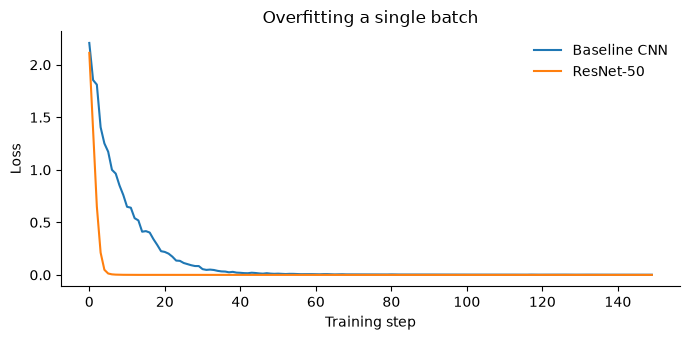

In [9]:
train_loader, _, _ = pp.get_loaders(batch_size=64, num_workers=0)
xb, yb = next(iter(train_loader))

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, model_type in [("Baseline CNN", "baseline_cnn"), ("ResNet-50", "resnet50_finetune")]:
    set_seed()
    losses, acc = overfit_one_batch(build_model(model_type), xb, yb, device, steps=150)
    print(f"{name}: loss {losses[0]:.3f} -> {losses[-1]:.4f} | accuracy on the batch {acc:.0%}")
    ax.plot(losses, label=name)
ax.set_xlabel("Training step"); ax.set_ylabel("Loss"); ax.set_title("Overfitting a single batch")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(pp.FIG_DIR / "overfit_one_batch.png", dpi=150)
plt.show()

### Prediction check

This confirms the pipeline can produce Kaggle predictions end to end: test images are loaded in `sample_submission.csv` order, passed through a model, and converted back to class names. An untrained model is used here, so the predicted classes are meaningless; only the format is being checked. Full predictions with the trained model are generated in Task 5.

In [10]:
preview = predict(baseline.to(device), test_loader, device, max_batches=1)
sample = pd.read_csv(pp.SAMPLE_SUB_CSV, dtype={"image_id": str})

same_order = (preview["image_id"].values == sample["image_id"].values[:len(preview)]).all()
valid_names = set(preview["class"]) <= set(pp.CLASS_NAMES)
print(f"IDs match sample_submission order: {same_order} | all class names valid: {valid_names}")
preview[["image_id", "class"]].head()

IDs match sample_submission order: True | all class names valid: True


,image_id,class
0,1,DogFace
1,2,DogFace
2,3,DogFace
3,4,DogFace
4,5,DogFace


## Task 4: Training Strategy and Overfitting/Underfitting Management

This section trains the three model versions defined in Task 3, monitors their learning behaviour, and diagnoses overfitting or underfitting from the learning curves.

**How monitoring works.** After every epoch, `training.fit()` records training loss and accuracy, validation loss and accuracy, and the learning rate. The history is saved to `outputs/history/<run>.csv` after each epoch, so progress is never lost. The weights from the epoch with the best validation accuracy are saved to `outputs/models/<run>.pt`, and training stops early if validation loss does not improve for several epochs.

**Re-running.** Finished runs are loaded from disk instead of retrained, so the notebook can be re-run safely. Set `retrain=True` in a run cell to train it again.

**Prerequisites:** the Task 3 cells have been run (they define `RUNS` and `device`). Runs must happen in order, because run 3 starts from run 2's weights.

**Expected time on an M3:** a few minutes per epoch for the ResNet-50 runs, so run 3 may take around an hour. Keep the Mac plugged in and awake while it trains.

### Setup

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import preprocessing as pp
from training import train_or_load, set_seed
from models import count_parameters

assert "RUNS" in globals() and "device" in globals(), "Run the Task 3 cells first (they define RUNS and device)."

# Parallel loading (4 worker processes) keeps the GPU supplied with batches during training
train_loader, val_loader, test_loader = pp.get_loaders(batch_size=64, num_workers=4)
print(f"Training batches per epoch: {len(train_loader)} | validation batches: {len(val_loader)} | device: {device}")

results = {}     # run name -> (model, history)

Training batches per epoch: 793 | validation batches: 199 | device: mps


### Run 1: Baseline CNN (trained from scratch)

Learns every weight from the training data alone. This shows what the data supports without prior knowledge, and is the reference point for measuring the benefit of transfer learning.

In [12]:
set_seed()
results["run1_baseline_cnn"] = train_or_load(RUNS[0], device, train_loader, val_loader, retrain=False)

[run1_baseline_cnn] parameters: 1,175,272 total, 1,175,272 trainable | device: mps
  epoch  1 | lr 1.00e-03 | train loss 1.3178 acc 0.5865 | val loss 1.3131 acc 0.6219 | 153s  *best
  epoch  2 | lr 9.96e-04 | train loss 0.8563 acc 0.8330 | val loss 0.8281 acc 0.8490 | 136s  *best
  epoch  3 | lr 9.84e-04 | train loss 0.7729 acc 0.8769 | val loss 0.7387 acc 0.8926 | 134s  *best
  epoch  4 | lr 9.65e-04 | train loss 0.7289 acc 0.8995 | val loss 0.7126 acc 0.9131 | 134s  *best
  epoch  5 | lr 9.38e-04 | train loss 0.7071 acc 0.9069 | val loss 0.6683 acc 0.9215 | 134s  *best
  epoch  6 | lr 9.05e-04 | train loss 0.6856 acc 0.9177 | val loss 0.6496 acc 0.9341 | 133s  *best
  epoch  7 | lr 8.64e-04 | train loss 0.6734 acc 0.9218 | val loss 0.6316 acc 0.9402 | 135s  *best
  epoch  8 | lr 8.19e-04 | train loss 0.6610 acc 0.9274 | val loss 0.6405 acc 0.9328 | 133s
  epoch  9 | lr 7.68e-04 | train loss 0.6518 acc 0.9306 | val loss 0.6437 acc 0.9328 | 138s
  epoch 10 | lr 7.13e-04 | train loss 0.

### Run 2: ResNet-50 with frozen backbone

Only the new 8-class output layer is trained, so ImageNet features are used as they are. This measures how well generic pretrained features transfer to this task, and it trains the output layer before fine-tuning so that run 3 starts from a stable point.

In [13]:
set_seed()
results["run2_resnet50_frozen"] = train_or_load(RUNS[1], device, train_loader, val_loader, retrain=False)

[run2_resnet50_frozen] parameters: 23,524,424 total, 16,392 trainable | device: mps
  epoch  1 | lr 1.00e-03 | train loss 0.9039 acc 0.7982 | val loss 0.7998 acc 0.8457 | 95s  *best
  epoch  2 | lr 9.05e-04 | train loss 0.8180 acc 0.8376 | val loss 0.7904 acc 0.8454 | 94s
  epoch  3 | lr 6.55e-04 | train loss 0.8048 acc 0.8483 | val loss 0.7707 acc 0.8673 | 94s  *best
  epoch  4 | lr 3.45e-04 | train loss 0.7945 acc 0.8527 | val loss 0.7702 acc 0.8601 | 94s
  epoch  5 | lr 9.55e-05 | train loss 0.7885 acc 0.8586 | val loss 0.7690 acc 0.8619 | 97s
[run2_resnet50_frozen] best val acc 0.8673 at epoch 3 | total time 7.9 min


### Run 3: ResNet-50 fully fine-tuned (main model)

Starts from run 2's weights and trains every layer with a smaller learning rate (1e-4), adapting the pretrained features to cat and dog facial features. A small learning rate is used so the useful pretrained features are adjusted rather than overwritten.

In [ ]:
set_seed()
results["run3_resnet50_finetune"] = train_or_load(RUNS[23], device, train_loader, val_loader, retrain=False)

Initialised from checkpoint: run2_resnet50_frozen
[run3_resnet50_finetune] parameters: 23,524,424 total, 23,524,424 trainable | device: mps
  epoch  1 | lr 1.00e-04 | train loss 0.6918 acc 0.8921 | val loss 0.5788 acc 0.9417 | 285s  *best
  epoch  2 | lr 9.89e-05 | train loss 0.5859 acc 0.9398 | val loss 0.5915 acc 0.9349 | 273s
  epoch  3 | lr 9.57e-05 | train loss 0.5697 acc 0.9479 | val loss 0.5547 acc 0.9525 | 452s  *best
  epoch  4 | lr 9.05e-05 | train loss 0.5591 acc 0.9526 | val loss 0.5537 acc 0.9531 | 273s  *best
  epoch  5 | lr 8.35e-05 | train loss 0.5524 acc 0.9565 | val loss 0.5616 acc 0.9477 | 270s
  epoch  6 | lr 7.50e-05 | train loss 0.5462 acc 0.9606 | val loss 0.5542 acc 0.9548 | 272s  *best
  epoch  7 | lr 6.55e-05 | train loss 0.5380 acc 0.9642 | val loss 0.5534 acc 0.9529 | 268s
  epoch  8 | lr 5.52e-05 | train loss 0.5309 acc 0.9677 | val loss 0.5744 acc 0.9455 | 1523s
  epoch  9 | lr 4.48e-05 | train loss 0.5232 acc 0.9732 | val loss 0.5673 acc 0.9482 | 274s
  e

### Learning curves

Loss and accuracy for training and validation at each epoch. The dashed line marks the epoch whose weights were kept (best validation accuracy).

**Reading the curves:**
- **Overfitting:** training loss keeps falling while validation loss rises, and a gap opens between training and validation accuracy.
- **Underfitting:** both training and validation accuracy stay low, or both curves are still improving when training ends.
- **Good fit:** both curves improve together and level off close to each other.

Note that training accuracy is measured on augmented images with dropout active, and the training loss includes label smoothing. Training accuracy can therefore sit slightly *below* validation accuracy without indicating a problem.

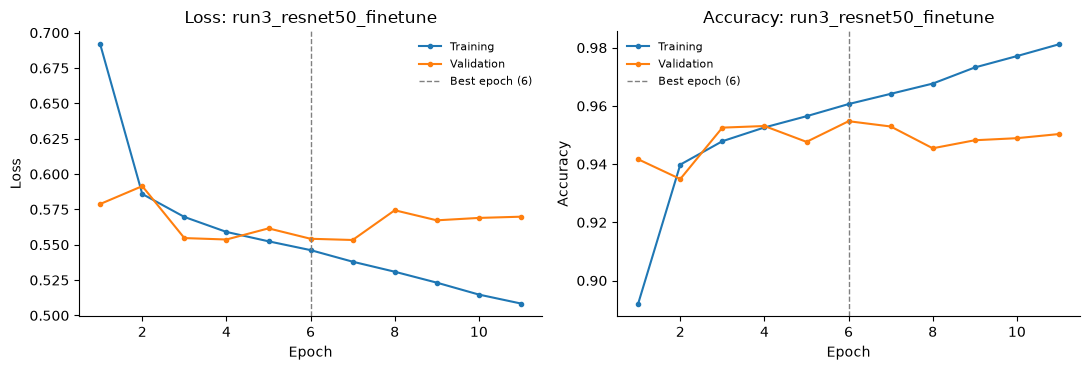

In [7]:
def plot_learning_curves(name, hist):
    best = hist.loc[hist["val_acc"].idxmax(), "epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric, label in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(hist["epoch"], hist[f"train_{metric}"], "o-", ms=3, label="Training")
        ax.plot(hist["epoch"], hist[f"val_{metric}"], "o-", ms=3, label="Validation")
        ax.axvline(best, color="grey", ls="--", lw=1, label=f"Best epoch ({int(best)})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(f"{label}: {name}")
        ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    fig.savefig(pp.FIG_DIR / f"learning_curves_{name}.png", dpi=150)
    plt.show()

for name, (_, hist) in results.items():
    plot_learning_curves(name, hist)

### Diagnosing overfitting and underfitting

The table summarises each run's behaviour. The **generalisation gap** is the training accuracy minus the validation accuracy in the final epoch: a large positive gap suggests overfitting. **Val loss rise** is how much validation loss increased from its lowest point to the final epoch: a clear rise means the model had started to overfit, and early stopping or best-epoch checkpointing protected against it.

In [10]:
rows = []
for name, (model, hist) in results.items():
    last, best = hist.iloc[-1], hist.loc[hist["val_acc"].idxmax()]
    gap = last["train_acc"] - last["val_acc"]
    loss_rise = last["val_loss"] - hist["val_loss"].min()
    planned = next(r.epochs for r in RUNS if r.name == name)
    if gap > 0.02 and loss_rise > 0.01:
        verdict = "Overfitting (controlled by early stopping / checkpoint)"
    elif best["val_acc"] < 0.90 or (len(hist) == planned and hist["val_acc"].iloc[-1] >= hist["val_acc"].max() - 1e-4):
        verdict = "Possible underfitting (still improving or low accuracy)"
    else:
        verdict = "Good fit"
    rows.append({"Run": name, "Epochs run": f"{len(hist)} / {planned}", "Best epoch": int(best["epoch"]),
                 "Best val acc": best["val_acc"], "Final train acc": last["train_acc"],
                 "Final val acc": last["val_acc"], "Generalisation gap": gap,
                 "Val loss rise": loss_rise, "Diagnosis": verdict})
diagnosis = pd.DataFrame(rows).set_index("Run")
diagnosis.to_csv(pp.OUTPUT_DIR / "training_diagnosis.csv")
diagnosis.style.format({c: "{:.4f}" for c in ["Best val acc", "Final train acc", "Final val acc",
                                              "Generalisation gap", "Val loss rise"]})

,Epochs run,Best epoch,Best val acc,Final train acc,Final val acc,Generalisation gap,Val loss rise,Diagnosis
Run,,,,,,,,
run3_resnet50_finetune,11 / 15,6,0.9548,0.9812,0.9503,0.0308,0.0165,Overfitting (controlled by early stopping / checkpoint)


The automatic diagnosis is a starting point only; the learning curves above are the main evidence and should be checked by eye.

### Strategies used to improve generalisation

| Strategy | Where it is applied | Effect |
|---|---|---|
| Data augmentation | Training images only (Task 2) | Increases variety so the model cannot memorise exact images |
| Dropout | Before the output layer (0.3 baseline, 0.2 ResNet-50) | Prevents reliance on any single feature |
| Weight decay | AdamW, 1e-4 | Penalises large weights, encouraging simpler solutions |
| Batch normalisation | Every convolutional layer | Stabilises training and has a mild regularising effect |
| Label smoothing | Loss, 0.1 | Discourages overconfident predictions on ambiguous crops |
| Cosine learning-rate schedule | All runs | Large steps early, fine adjustments late |
| Early stopping and best-epoch checkpoint | All runs | Stops training and keeps the weights before overfitting sets in |
| Transfer learning and fine-tuning | Runs 2 and 3 | Starts from features learned on 1.2 million images, reducing the data needed |

### Run comparison

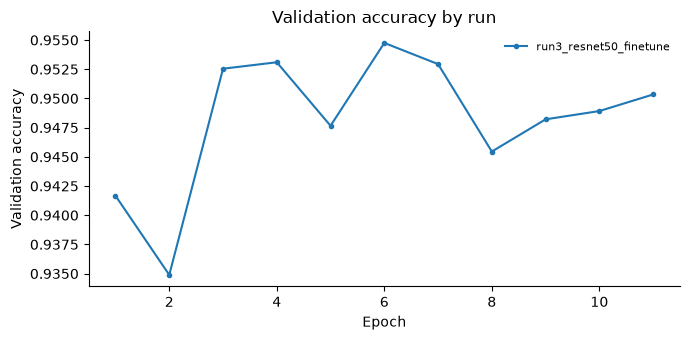

,Trainable parameters,Best val acc,Val loss at best,Best epoch,Epochs run,Training time (min)
Run,,,,,,
run3_resnet50_finetune,"23,524,424",0.9548,0.5542,6,11,73.9


In [11]:
rows = []
for name, (model, hist) in results.items():
    best = hist.loc[hist["val_acc"].idxmax()]
    total, trainable = count_parameters(model)
    rows.append({"Run": name, "Trainable parameters": trainable, "Best val acc": best["val_acc"],
                 "Val loss at best": best["val_loss"], "Best epoch": int(best["epoch"]),
                 "Epochs run": len(hist), "Training time (min)": hist["seconds"].sum() / 60})
comparison = pd.DataFrame(rows).set_index("Run")
comparison.to_csv(pp.OUTPUT_DIR / "run_comparison.csv")

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, (_, hist) in results.items():
    ax.plot(hist["epoch"], hist["val_acc"], "o-", ms=3, label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy"); ax.set_title("Validation accuracy by run")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); fig.savefig(pp.FIG_DIR / "val_accuracy_comparison.png", dpi=150); plt.show()

comparison.style.format({"Trainable parameters": "{:,}", "Best val acc": "{:.4f}",
                         "Val loss at best": "{:.4f}", "Training time (min)": "{:.1f}"})

### Changes made and justification

Run 2 underfitted, reaching only 86.7% validation accuracy with training accuracy below validation, because a single linear layer on fixed ImageNet features could not separate these classes. This motivated fine-tuning the full network in run 3, which raised validation accuracy to 95.5%. Run 3 began overfitting after epoch 6: training accuracy kept rising to 98.1% while validation loss increased from 0.553 to 0.570. Early stopping ended training at epoch 11 and the epoch 6 weights were kept, so no further changes were made. Stronger regularisation was considered but not pursued, since both the baseline and the fine-tuned model levelled off near 95%, suggesting the remaining errors stem mainly from the data rather than the model.

Histories found in /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/history: ['run1_baseline_cnn', 'run2_resnet50_frozen', 'run3_resnet50_finetune']


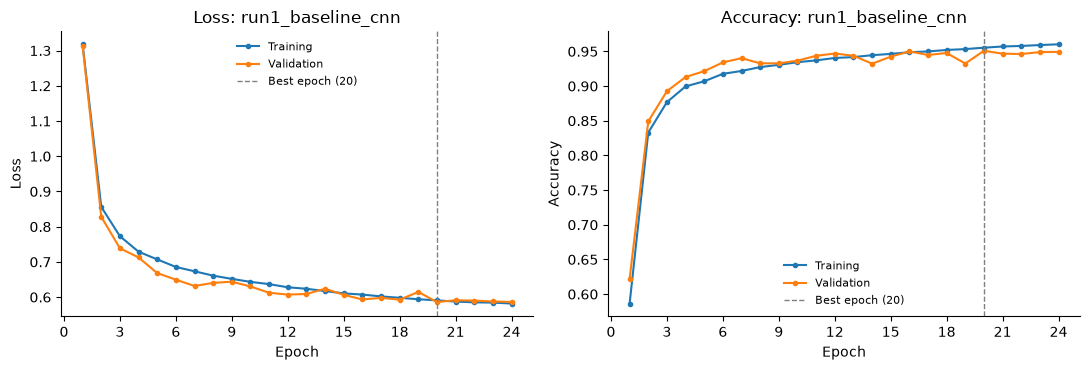

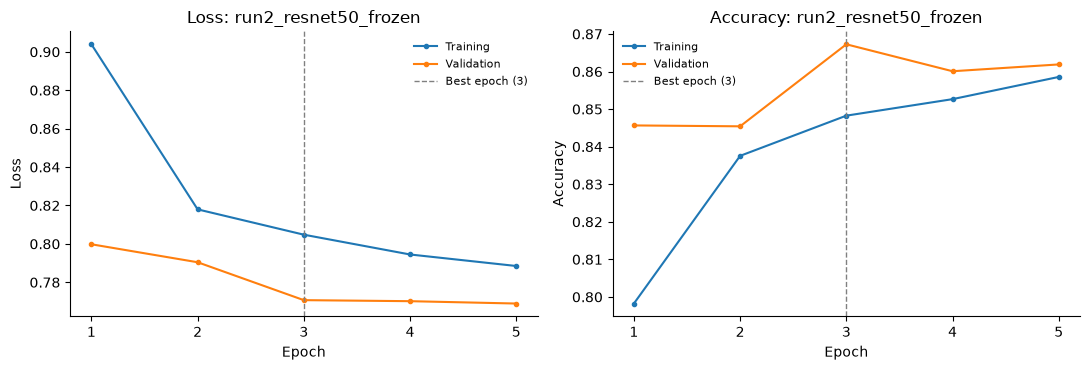

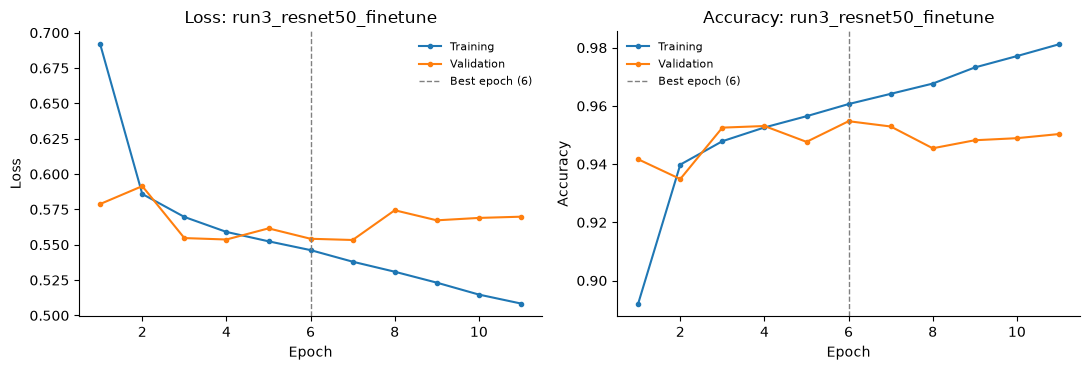

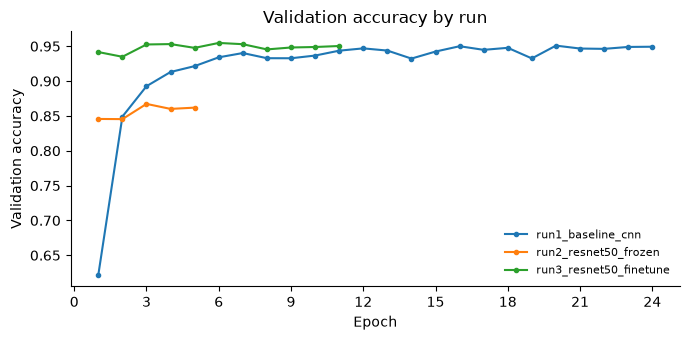

Saved figures:
  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/learning_curves_run1_baseline_cnn.png  (83 KB)
  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/learning_curves_run2_resnet50_frozen.png  (82 KB)
  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/learning_curves_run3_resnet50_finetune.png  (83 KB)
  /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/figures/val_accuracy_comparison.png  (44 KB)


In [27]:
# Export learning-curve figures from the saved training histories (no retraining needed)
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import preprocessing as pp

HISTORY_DIR = pp.OUTPUT_DIR / "history"
pp.FIG_DIR.mkdir(parents=True, exist_ok=True)
histories = {f.stem: pd.read_csv(f) for f in sorted(HISTORY_DIR.glob("*.csv"))}
print(f"Histories found in {HISTORY_DIR}: {list(histories)}")

saved = []
for name, hist in histories.items():
    best = hist.loc[hist["val_acc"].idxmax(), "epoch"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric, label in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy")]:
        ax.plot(hist["epoch"], hist[f"train_{metric}"], "o-", ms=3, label="Training")
        ax.plot(hist["epoch"], hist[f"val_{metric}"], "o-", ms=3, label="Validation")
        ax.axvline(best, color="grey", ls="--", lw=1, label=f"Best epoch ({int(best)})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(f"{label}: {name}")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout()
    path = pp.FIG_DIR / f"learning_curves_{name}.png"
    fig.savefig(path, dpi=150); saved.append(path)
    plt.show()

# All runs' validation accuracy on one chart
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, hist in histories.items():
    ax.plot(hist["epoch"], hist["val_acc"], "o-", ms=3, label=name)
ax.set_xlabel("Epoch"); ax.set_ylabel("Validation accuracy"); ax.set_title("Validation accuracy by run")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
path = pp.FIG_DIR / "val_accuracy_comparison.png"
fig.savefig(path, dpi=150); saved.append(path)
plt.show()

print("Saved figures:")
for p in saved:
    print(f"  {p.resolve()}  ({p.stat().st_size // 1024} KB)")

## Task 5: Model Evaluation and Kaggle Submission

This section evaluates the trained models on the validation set, examines the final model's per-class performance, and generates the Kaggle submission file.

**Final model:** run 3, the fine-tuned ResNet-50, which achieved the highest validation accuracy in Task 4.

**Prerequisites:** the three Task 4 runs have finished, so their weights are saved in `outputs/models/`. This section loads the saved weights, so it does not depend on the Task 4 cells being run in the current session.

Data is loaded in the main process (`num_workers=0`) here. Evaluation needs only one pass over the data, so the speed cost is small, and it avoids the worker-process issues that can follow an interrupted session.

### Setup

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import preprocessing as pp
from training import load_trained_model, evaluate, predict, write_submission, set_seed

set_seed()
device = pp.get_device()
_, val_loader, test_loader = pp.get_loaders(batch_size=128, num_workers=0)
val_df = pd.read_csv(pp.SPLIT_DIR / "val.csv", dtype={"image_id": str})   # same order as val_loader

# Same loss as training (with label smoothing), so these figures match the Task 4 learning curves
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

RUN_MODELS = {"run1_baseline_cnn": "baseline_cnn",
              "run2_resnet50_frozen": "resnet50_frozen",
              "run3_resnet50_finetune": "resnet50_finetune"}
FINAL_RUN = "run3_resnet50_finetune"
print(f"Validation images: {len(val_df)} | test images: {len(test_loader.dataset)} | device: {device}")

Validation images: 12686 | test images: 29443 | device: mps


### Validation metrics for all runs

Each saved model is evaluated on the full validation set. Accuracy is the Kaggle metric, while macro-averaged F1 gives every class equal weight, so it would reveal weak performance on the smaller classes that accuracy could hide (Section 1.4).

In [13]:
eval_rows, outputs = [], {}
for run, model_type in RUN_MODELS.items():
    model = load_trained_model(run, model_type, device)
    loss, acc, y_true, y_pred, probs = evaluate(model, val_loader, criterion, device, return_outputs=True)
    outputs[run] = (y_true, y_pred, probs)
    eval_rows.append({"Run": run, "Val loss": loss, "Val accuracy": acc,
                      "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
                      "Weighted F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
                      "Errors": int((y_true != y_pred).sum())})
    print(f"{run}: accuracy {acc:.4f}, loss {loss:.4f}")

val_results = pd.DataFrame(eval_rows).set_index("Run")
val_results.to_csv(pp.OUTPUT_DIR / "validation_results.csv")
val_results.style.format({"Val loss": "{:.4f}", "Val accuracy": "{:.4f}",
                          "Macro F1": "{:.4f}", "Weighted F1": "{:.4f}"})

run1_baseline_cnn: accuracy 0.9509, loss 0.5860
run2_resnet50_frozen: accuracy 0.8673, loss 0.7707
run3_resnet50_finetune: accuracy 0.9548, loss 0.5542


,Val loss,Val accuracy,Macro F1,Weighted F1,Errors
Run,,,,,
run1_baseline_cnn,0.5860,0.9509,0.9443,0.9506,623
run2_resnet50_frozen,0.7707,0.8673,0.8396,0.8659,1684
run3_resnet50_finetune,0.5542,0.9548,0.9483,0.9548,574


### Final model: per-class precision, recall and F1

- **Precision:** of the images predicted as a class, the share that truly belong to it.
- **Recall (class-level accuracy):** of the images truly in a class, the share the model found.
- **F1:** the harmonic mean of precision and recall.

In [14]:
y_true, y_pred, probs = outputs[FINAL_RUN]

report = pd.DataFrame(classification_report(y_true, y_pred, labels=range(8), target_names=pp.CLASS_NAMES,
                                             output_dict=True, digits=4, zero_division=0)).T
report["support"] = report["support"].astype(int)
report.to_csv(pp.OUTPUT_DIR / "classification_report_final.csv")

# Save every validation prediction for the error analysis in Task 6
val_pred = val_df.assign(true=[pp.IDX_TO_CLASS[i] for i in y_true],
                         pred=[pp.IDX_TO_CLASS[i] for i in y_pred],
                         confidence=probs.max(1))
for i, c in enumerate(pp.CLASS_NAMES):
    val_pred[f"p_{c}"] = probs[:, i]
val_pred.to_csv(pp.OUTPUT_DIR / "val_predictions_final.csv", index=False)

report.style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1-score": "{:.4f}"})

,precision,recall,f1-score,support
CatEye,0.9982,0.9971,0.9976,2754
DogEye,0.9978,0.9965,0.9972,2313
CatFace,1.0000,0.9950,0.9975,1387
DogFace,0.9966,1.0000,0.9983,1157
CatMouth,0.7828,0.8452,0.8128,1382
DogMouth,0.9940,0.9957,0.9948,1158
CatNose,0.8255,0.7656,0.7944,1378
DogNose,0.9948,0.9922,0.9935,1157
accuracy,0.9548,0.9548,0.9548,0
macro avg,0.9487,0.9484,0.9483,12686


### Confusion matrix

Rows are the true classes and columns the predicted classes, so the diagonal holds correct predictions and every off-diagonal cell is a specific kind of error. The left matrix shows counts; the right shows each row as a percentage, which makes classes of different sizes comparable.

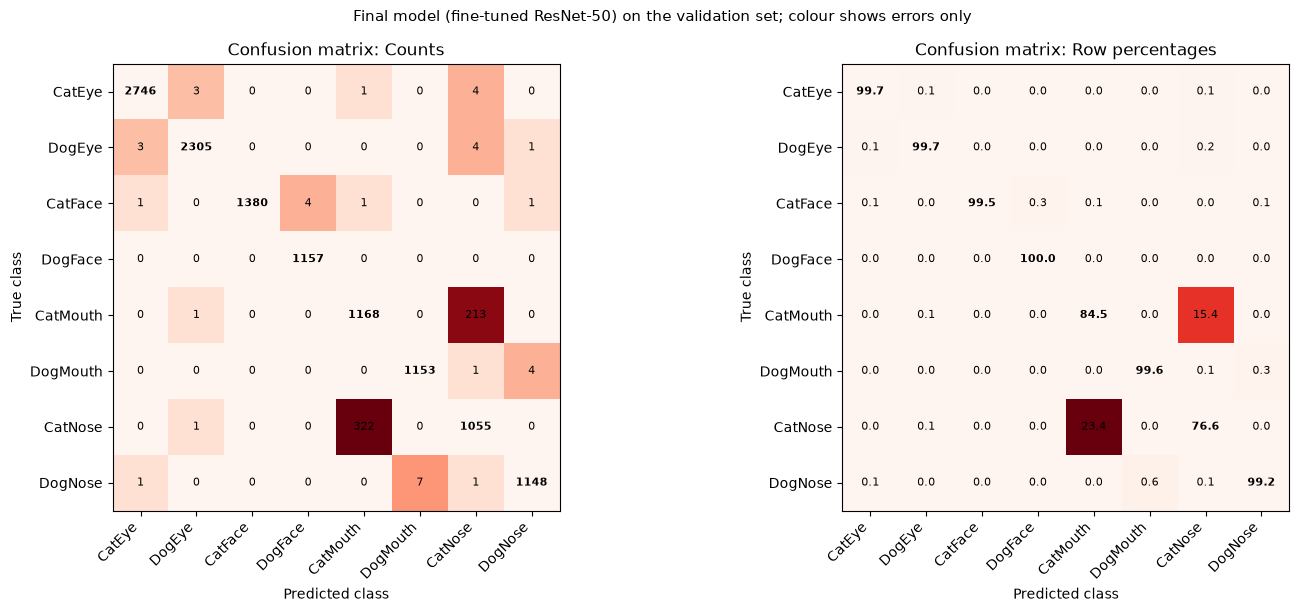

Most frequent errors:


,True class,Predicted as,Count
0,CatNose,CatMouth,322
1,CatMouth,CatNose,213
2,DogNose,DogMouth,7
3,CatEye,CatNose,4
4,DogEye,CatNose,4
5,CatFace,DogFace,4
6,DogMouth,DogNose,4
7,CatEye,DogEye,3


In [15]:
cm = confusion_matrix(y_true, y_pred, labels=range(8))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
for ax, data, title, fmt in [(axes[0], cm, "Counts", "{:d}"), (axes[1], cm_pct, "Row percentages", "{:.1f}")]:
    shown = np.where(np.eye(8, dtype=bool), np.nan, data)          # colour by errors so they stand out
    ax.imshow(np.log1p(np.nan_to_num(shown)) if title == "Counts" else np.nan_to_num(shown), cmap="Reds")
    for i in range(8):
        for j in range(8):
            ax.text(j, i, fmt.format(data[i, j]), ha="center", va="center", fontsize=8,
                    fontweight="bold" if i == j else "normal")
    ax.set_xticks(range(8), pp.CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(8), pp.CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(f"Confusion matrix: {title}")
fig.suptitle("Final model (fine-tuned ResNet-50) on the validation set; colour shows errors only", fontsize=11)
plt.tight_layout()
fig.savefig(pp.FIG_DIR / "confusion_matrix_final.png", dpi=150)
plt.show()

errors = [(pp.CLASS_NAMES[i], pp.CLASS_NAMES[j], cm[i, j]) for i in range(8) for j in range(8) if i != j]
top = pd.DataFrame(sorted(errors, key=lambda e: -e[2])[:8], columns=["True class", "Predicted as", "Count"])
print("Most frequent errors:")
top

### Generate Kaggle predictions

The final model predicts every test image. Test images go through exactly the same evaluation transform as validation images, and they are processed in `sample_submission.csv` order. `write_submission` then checks the file before saving: the same IDs in the same order as the sample, and only the eight official class names.

In [16]:
final_model = load_trained_model(FINAL_RUN, RUN_MODELS[FINAL_RUN], device)
test_pred = predict(final_model, test_loader, device)
test_pred.to_csv(pp.OUTPUT_DIR / "test_predictions_with_confidence.csv", index=False)

SUBMISSION_PATH = pp.OUTPUT_DIR / "submission.csv"
submission = write_submission(test_pred, SUBMISSION_PATH)

# Sanity check: the predicted class mix should resemble the training class mix
mix = pd.DataFrame({"Test predictions (%)": submission["class"].value_counts(normalize=True) * 100,
                    "Training labels (%)": pd.read_csv(pp.SPLIT_DIR / "train.csv")["label"].value_counts(normalize=True) * 100}
                   ).reindex(pp.CLASS_NAMES).fillna(0).round(2)
print(f"Mean prediction confidence: {test_pred['confidence'].mean():.3f}")
display(submission.head())
mix

Saved submission: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/submission.csv (29443 rows)
Mean prediction confidence: 0.865


,image_id,class
0,1,DogEye
1,2,DogNose
2,3,DogNose
3,4,DogFace
4,5,CatMouth


,Test predictions (%),Training labels (%)
CatEye,21.77,21.71
DogEye,18.37,18.23
CatFace,10.60,10.94
DogFace,9.53,9.12
CatMouth,10.67,10.89
DogMouth,9.37,9.13
CatNose,10.55,10.86
DogNose,9.13,9.12


### Kaggle submission

1. Upload `outputs/submission.csv` on the competition's **Submit Predictions** page.
2. Take a screenshot of the leaderboard entry showing your **Kaggle username** and **score**, for the report (Task 7 requires this evidence).
3. Enter the score below.

Leaderboard scores should not be used to tune the model further, so model choices remain based on validation results (Section 1.7).

In [17]:
KAGGLE_USERNAME = "christiancantos"   # replace with your Kaggle username
KAGGLE_SCORE = 0.9242                         # replace with your public leaderboard accuracy, e.g. 0.9512

val_acc = val_results.loc[FINAL_RUN, "Val accuracy"]
n_val = len(val_df)
se = np.sqrt(val_acc * (1 - val_acc) / n_val)     # standard error of the validation accuracy
print(f"Validation accuracy: {val_acc:.4f} (95% interval about {val_acc - 1.96 * se:.4f} to {val_acc + 1.96 * se:.4f})")
if KAGGLE_SCORE is not None:
    diff = KAGGLE_SCORE - val_acc
    print(f"Kaggle accuracy ({KAGGLE_USERNAME}): {KAGGLE_SCORE:.4f} | difference from validation: {diff:+.4f} "
          f"({diff * 100:+.2f} percentage points)")
    print("Within the validation interval: consistent generalisation" if abs(diff) <= 1.96 * se else
          "Outside the validation interval: see the discussion of possible causes in Task 6")

Validation accuracy: 0.9548 (95% interval about 0.9511 to 0.9584)
Kaggle accuracy (christiancantos): 0.9242 | difference from validation: -0.0306 (-3.06 percentage points)
Outside the validation interval: see the discussion of possible causes in Task 6


## Task 6: Results Analysis and Improvement Strategies

This section analyses where and why the final model makes mistakes, investigates the gap between validation accuracy and the Kaggle score, and tests three improvement strategies that need no retraining:

1. **Test-time augmentation (TTA):** average predictions for each image and its horizontal mirror.
2. **Ensembling:** average the predicted probabilities of the baseline CNN and the fine-tuned ResNet-50.
3. **Crop-shape rule:** use each image's original aspect ratio to decide between Mouth and Nose, the pair that centre-cropping made hard to separate.

Every combination is evaluated on the validation set, and the best is chosen **by validation accuracy only**, then submitted to Kaggle once. This keeps model selection independent of the leaderboard.

**Prerequisites:** the Task 4 runs are saved, and `outputs/quality_metrics.csv` (from Task 1) exists, since it holds the original image dimensions.

### Setup and cached predictions

Predicted probabilities for both models, on validation and test images, with and without horizontal flipping, are computed once and saved to `outputs/probs/`. Later runs of this cell load them from disk in seconds.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from pathlib import Path
from scipy.stats import binomtest

import preprocessing as pp
from training import load_trained_model, write_submission, set_seed

set_seed()
device = pp.get_device()
PROB_DIR = pp.OUTPUT_DIR / "probs"
PROB_DIR.mkdir(parents=True, exist_ok=True)
_, val_loader, test_loader = pp.get_loaders(batch_size=128, num_workers=0)

val_df = pd.read_csv(pp.SPLIT_DIR / "val.csv", dtype={"image_id": str})
test_df = pd.read_csv(pp.SPLIT_DIR / "test.csv", dtype={"image_id": str})
y_val = val_df["label"].map(pp.CLASS_TO_IDX).to_numpy()

MODELS = {"baseline": ("run1_baseline_cnn", "baseline_cnn"),
          "resnet": ("run3_resnet50_finetune", "resnet50_finetune")}

@torch.no_grad()
def compute_probs(model, loader, flip):
    out = []
    for x, _ in loader:
        x = x.to(device)
        if flip:
            x = torch.flip(x, dims=[3])          # horizontal mirror
        out.append(torch.softmax(model(x), 1).cpu())
    return torch.cat(out).numpy()

probs = {}
for key, (run, model_type) in MODELS.items():
    model = None
    for split, loader in [("val", val_loader), ("test", test_loader)]:
        for flip in [False, True]:
            path = PROB_DIR / f"{key}_{split}_{'flip' if flip else 'orig'}.npy"
            if not path.exists():
                model = model or load_trained_model(run, model_type, device)
                print(f"Computing {path.name} ...")
                np.save(path, compute_probs(model, loader, flip))
            probs[(key, split, flip)] = np.load(path)
print("Cached probabilities:", sorted(p.name for p in PROB_DIR.glob("*.npy")))

# Original image dimensions (from Task 1), matched by file name
q = pd.read_csv(pp.QUALITY_CSV, dtype={"image_id": str}, low_memory=False)
dims = q.set_index(["split", "image_id"])[["width", "height"]]
def original_dims(df, split):
    stems = df["path"].map(lambda p: Path(p).stem)
    d = dims.loc[[(split, s) for s in stems]].to_numpy(dtype=float)
    return d[:, 0], d[:, 1]
val_w, val_h = original_dims(val_df, "train")      # validation images come from train/
test_w, test_h = original_dims(test_df, "test")
val_aspect, test_aspect = val_w / val_h, test_w / test_h

base_pred = probs[("resnet", "val", False)].argmax(1)
print(f"Final model validation accuracy (check): {(base_pred == y_val).mean():.4f}")

Computing baseline_val_orig.npy ...
Computing baseline_val_flip.npy ...
Computing baseline_test_orig.npy ...
Computing baseline_test_flip.npy ...
Computing resnet_val_orig.npy ...
Computing resnet_val_flip.npy ...
Computing resnet_test_orig.npy ...
Computing resnet_test_flip.npy ...
Cached probabilities: ['baseline_test_flip.npy', 'baseline_test_orig.npy', 'baseline_val_flip.npy', 'baseline_val_orig.npy', 'resnet_test_flip.npy', 'resnet_test_orig.npy', 'resnet_val_flip.npy', 'resnet_val_orig.npy']
Final model validation accuracy (check): 0.9548


### Error breakdown: species errors versus part errors

Each error is classified by what the model got wrong: the **species** (cat or dog), the **facial part** (eye, face, mouth or nose), or both.

In [19]:
names = np.array(pp.CLASS_NAMES)
true_c, pred_c = names[y_val], names[base_pred]
err = true_c != pred_c
species_wrong = np.array([t[:3] != p[:3] for t, p in zip(true_c, pred_c)])
part_wrong = np.array([t[3:] != p[3:] for t, p in zip(true_c, pred_c)])

breakdown = pd.Series({
    "Part wrong, species right": int((err & part_wrong & ~species_wrong).sum()),
    "Species wrong, part right": int((err & species_wrong & ~part_wrong).sum()),
    "Both wrong": int((err & species_wrong & part_wrong).sum()),
}, name="Errors").to_frame()
breakdown["Share of errors (%)"] = (breakdown["Errors"] / err.sum() * 100).round(1)
cat_mn = ((true_c == "CatMouth") & (pred_c == "CatNose")) | ((true_c == "CatNose") & (pred_c == "CatMouth"))
print(f"Total errors: {err.sum()} | CatMouth <-> CatNose confusions: {cat_mn.sum()} ({cat_mn.sum() / err.sum():.1%} of errors)")
breakdown

Total errors: 574 | CatMouth <-> CatNose confusions: 535 (93.2% of errors)


,Errors,Share of errors (%)
"Part wrong, species right",554,96.5
"Species wrong, part right",11,1.9
Both wrong,9,1.6


### Why CatMouth and CatNose are confused

Task 1 found that mouth crops are wide (aspect ratio about 1.4) and centred on the nose, while nose crops are square. Centre-cropping turns a mouth crop into a square around the nose, so both classes end up showing similar content. If that explanation is right, the **original** shapes of the confused images should still separate them clearly, even though the model, which only sees the cropped square, cannot.

Original aspect ratios of the confused CatMouth/CatNose images:


,count,min,50%,max,share wider than 1.2 (%)
true,,,,,
CatMouth,213.0,1.375,1.423,2.062,100.000
CatNose,322.0,1.000,1.000,2.045,0.621


A shape rule (wider than 1.2 -> Mouth) would correctly separate 99.6% of these errors.


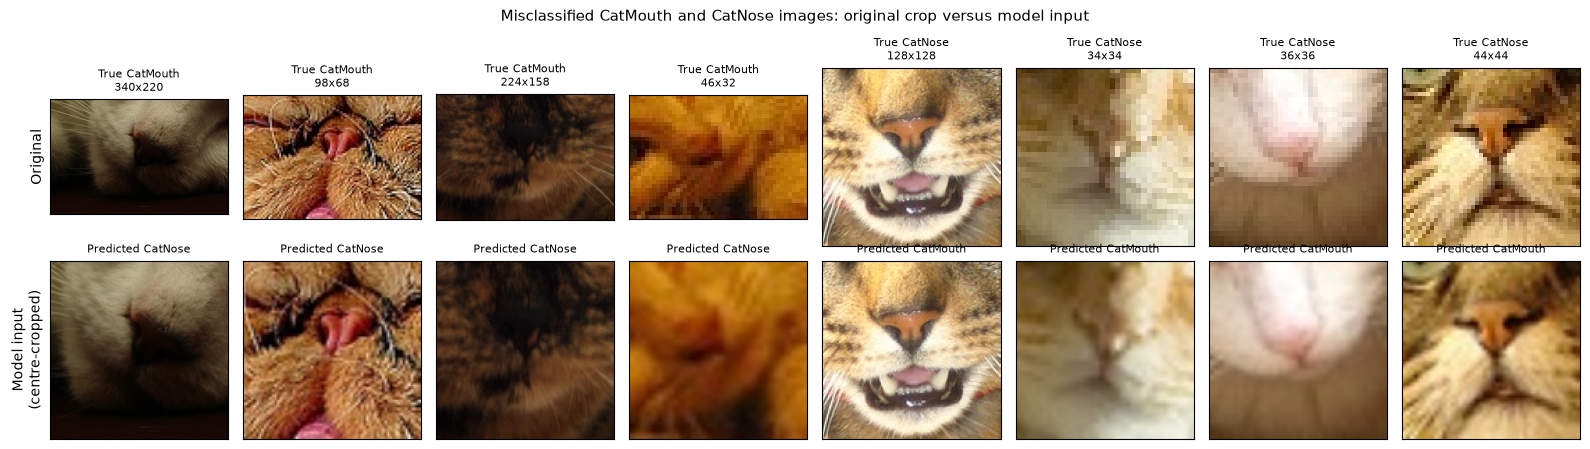

In [20]:
confused = val_df[cat_mn].assign(true=true_c[cat_mn], pred=pred_c[cat_mn], aspect=val_aspect[cat_mn])
shape_table = confused.groupby("true")["aspect"].describe()[["count", "min", "50%", "max"]]
shape_table["share wider than 1.2 (%)"] = confused.groupby("true")["aspect"].apply(lambda a: (a > 1.2).mean() * 100)
print("Original aspect ratios of the confused CatMouth/CatNose images:")
display(shape_table.round(3))
separable = ((confused["true"] == "CatMouth") & (confused["aspect"] > 1.2)) | \
            ((confused["true"] == "CatNose") & (confused["aspect"] <= 1.2))
print(f"A shape rule (wider than 1.2 -> Mouth) would correctly separate {separable.mean():.1%} of these errors.")

# Visual evidence: original crops beside what the model actually sees after centre-cropping
eval_tf = pp.get_eval_transform()
examples = pd.concat([confused[confused["true"] == c].sample(min(4, (confused["true"] == c).sum()),
                                                              random_state=pp.SEED) for c in ["CatMouth", "CatNose"]])
n_ex = max(len(examples), 1)
fig, axes = plt.subplots(2, n_ex, figsize=(2 * n_ex, 4.6), squeeze=False)
for j, (_, r) in enumerate(examples.iterrows()):
    with Image.open(pp.PROJECT_ROOT / r["path"]) as img:
        img = img.convert("RGB")
    axes[0, j].imshow(img); axes[0, j].set_title(f"True {r['true']}\n{img.width}x{img.height}", fontsize=8)
    axes[1, j].imshow(pp.denormalise(eval_tf(img)).permute(1, 2, 0).numpy())
    axes[1, j].set_title(f"Predicted {r['pred']}", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("Model input\n(centre-cropped)")
fig.suptitle("Misclassified CatMouth and CatNose images: original crop versus model input", fontsize=11)
plt.tight_layout(); fig.savefig(pp.FIG_DIR / "catmouth_catnose_errors.png", dpi=150); plt.show()

### Validation versus Kaggle: does image size explain the gap?

The Kaggle score (92.42%) is about 3 points below validation accuracy (95.48%). The test set contains slightly more small images than the training data (Task 1). This cell measures validation accuracy for each image-size group, then re-weights it by the test set's size mix. If the re-weighted estimate stays close to validation accuracy, image size explains little of the gap, which points instead to the source-photo leakage risk identified in Section 1.6.

In [21]:
KAGGLE_SCORE = 0.9242
bins = [0, 32, 64, 128, np.inf]
labels = ["< 32 px", "32-63 px", "64-127 px", "128+ px"]
val_group = pd.cut(np.minimum(val_w, val_h), bins, labels=labels, right=False)
test_group = pd.cut(np.minimum(test_w, test_h), bins, labels=labels, right=False)

size_table = pd.DataFrame({
    "Val images": pd.Series(val_group).value_counts().reindex(labels),
    "Val accuracy": pd.Series(base_pred == y_val).groupby(val_group, observed=False).mean().reindex(labels).to_numpy(),
    "Val share (%)": pd.Series(val_group).value_counts(normalize=True).reindex(labels) * 100,
    "Test share (%)": pd.Series(test_group).value_counts(normalize=True).reindex(labels) * 100,
})
reweighted = (size_table["Val accuracy"] * size_table["Test share (%)"] / 100).sum()
print(f"Validation accuracy: {(base_pred == y_val).mean():.4f} | re-weighted to the test size mix: {reweighted:.4f} | "
      f"Kaggle: {KAGGLE_SCORE:.4f}")
print(f"Gap explained by image size: {(base_pred == y_val).mean() - reweighted:+.4f} of the "
      f"{(base_pred == y_val).mean() - KAGGLE_SCORE:+.4f} total")
size_table.round(3)

Validation accuracy: 0.9548 | re-weighted to the test size mix: 0.9538 | Kaggle: 0.9242
Gap explained by image size: +0.0010 of the +0.0306 total


,Val images,Val accuracy,Val share (%),Test share (%)
< 32 px,770,0.918,6.070,8.226
32-63 px,3922,0.952,30.916,32.181
64-127 px,4827,0.954,38.050,35.798
128+ px,3167,0.968,24.965,23.795


### Is the fine-tuned ResNet-50 significantly better than the baseline?

The two models differ by only 0.39 points of validation accuracy. **McNemar's test** compares two models on the same images by looking only at the images where exactly one of them is correct. If those disagreements split roughly evenly, the difference could be chance.

In [22]:
def mcnemar(pred_a, pred_b, y):
    a_only = int(((pred_a == y) & (pred_b != y)).sum())
    b_only = int(((pred_a != y) & (pred_b == y)).sum())
    p = binomtest(min(a_only, b_only), a_only + b_only, 0.5).pvalue if a_only + b_only else 1.0
    return a_only, b_only, p

b_only_correct, r_only_correct, p = mcnemar(probs[("baseline", "val", False)].argmax(1), base_pred, y_val)
print(f"Baseline right, ResNet-50 wrong: {b_only_correct} | ResNet-50 right, baseline wrong: {r_only_correct} | "
      f"McNemar p-value: {p:.4f}")
print("Significant at the 5% level" if p < 0.05 else "Not significant at the 5% level: the difference could be chance")

Baseline right, ResNet-50 wrong: 205 | ResNet-50 right, baseline wrong: 254 | McNemar p-value: 0.0250
Significant at the 5% level


### Improvement experiments

All eight combinations of the three strategies are evaluated on the validation set:

- **TTA:** average of the original and horizontally flipped predictions.
- **Ensemble:** equal-weight average of the baseline and ResNet-50 probabilities. Equal weights are used, rather than weights tuned on validation, to avoid fitting the validation set.
- **Shape rule:** when the prediction is a Mouth or Nose class, the original aspect ratio decides between the two for that species (wider than 1.2 means Mouth). The 1.2 threshold comes from the training-data analysis in Task 1, not from validation results.

The shape rule deliberately reintroduces the crop-shape information that centre-cropping removed. It is legitimate for this competition, because image dimensions are part of the input and the test set shares the same cropping, but it relies on a property of this dataset that would not hold for differently cropped images.

In [23]:
SHAPE_THRESHOLD = 1.2

def combine(split, ensemble, tta):
    keys = ["resnet"] + (["baseline"] if ensemble else [])
    flips = [False, True] if tta else [False]
    return np.mean([probs[(k, split, f)] for k in keys for f in flips], axis=0)

def apply_shape_rule(pred, aspect):
    pred = pred.copy()
    wide = aspect > SHAPE_THRESHOLD
    for sp in ["Cat", "Dog"]:
        mouth, nose = pp.CLASS_TO_IDX[f"{sp}Mouth"], pp.CLASS_TO_IDX[f"{sp}Nose"]
        in_pair = np.isin(pred, [mouth, nose])
        pred[in_pair & wide] = mouth
        pred[in_pair & ~wide] = nose
    return pred

def method_pred(split, ensemble, tta, shape):
    pred = combine(split, ensemble, tta).argmax(1)
    return apply_shape_rule(pred, val_aspect if split == "val" else test_aspect) if shape else pred

rows = []
for ensemble in [False, True]:
    for tta in [False, True]:
        for shape in [False, True]:
            pred = method_pred("val", ensemble, tta, shape)
            _, _, p = mcnemar(base_pred, pred, y_val)
            rows.append({"Ensemble": ensemble, "TTA": tta, "Shape rule": shape,
                         "Val accuracy": (pred == y_val).mean(), "Errors": int((pred != y_val).sum()),
                         "Change vs final model": (pred == y_val).mean() - (base_pred == y_val).mean(),
                         "McNemar p vs final model": p})
experiments = pd.DataFrame(rows)
experiments.to_csv(pp.OUTPUT_DIR / "improvement_experiments.csv", index=False)

best = experiments.loc[experiments["Val accuracy"].idxmax()]
print(f"Best on validation: ensemble={best['Ensemble']}, TTA={best['TTA']}, shape rule={best['Shape rule']} "
      f"-> {best['Val accuracy']:.4f}")
experiments.style.format({"Val accuracy": "{:.4f}", "Change vs final model": "{:+.4f}",
                          "McNemar p vs final model": "{:.4f}"}).highlight_max(subset=["Val accuracy"])

Best on validation: ensemble=True, TTA=True, shape rule=True -> 0.9976


,Ensemble,TTA,Shape rule,Val accuracy,Errors,Change vs final model,McNemar p vs final model
0,False,False,False,0.9548,574,+0.0000,1.0000
1,False,False,True,0.9969,39,+0.0422,0.0000
2,False,True,False,0.9559,560,+0.0011,0.2614
3,False,True,True,0.9972,36,+0.0424,0.0000
4,True,False,False,0.9589,522,+0.0041,0.0001
5,True,False,True,0.9973,34,+0.0426,0.0000
6,True,True,False,0.9586,525,+0.0039,0.0010
7,True,True,True,0.9976,31,+0.0428,0.0000


### Per-class effect of the best method

In [24]:
best_val = method_pred("val", best["Ensemble"], best["TTA"], best["Shape rule"])
per_class = pd.DataFrame({
    "Final model recall": pd.Series(base_pred == y_val).groupby(y_val).mean().to_numpy(),
    "Best method recall": pd.Series(best_val == y_val).groupby(y_val).mean().to_numpy(),
}, index=pp.CLASS_NAMES)
per_class["Change"] = per_class["Best method recall"] - per_class["Final model recall"]
per_class.style.format("{:.4f}")

,Final model recall,Best method recall,Change
CatEye,0.9971,0.9975,0.0004
DogEye,0.9965,0.9987,0.0022
CatFace,0.9950,0.9957,0.0007
DogFace,1.0000,1.0000,0.0000
CatMouth,0.8452,1.0000,0.1548
DogMouth,0.9957,0.9974,0.0017
CatNose,0.7656,0.9920,0.2264
DogNose,0.9922,0.9991,0.0069


### Improved Kaggle submission

The best method, chosen on validation, predicts the test set. Submit `outputs/submission_improved.csv` once and record the score below.

In [25]:
best_test = method_pred("test", best["Ensemble"], best["TTA"], best["Shape rule"])
improved = pd.DataFrame({"image_id": test_df["image_id"], "class": names[best_test]})
write_submission(improved, pp.OUTPUT_DIR / "submission_improved.csv")

changed = (improved["class"].to_numpy() != pd.read_csv(pp.OUTPUT_DIR / "submission.csv")["class"].to_numpy())
print(f"Test predictions changed from the first submission: {changed.sum()} ({changed.mean():.1%})")

IMPROVED_KAGGLE_SCORE = None    # replace with the new public leaderboard accuracy after submitting
if IMPROVED_KAGGLE_SCORE is not None:
    print(f"Kaggle: first submission {KAGGLE_SCORE:.4f} -> improved {IMPROVED_KAGGLE_SCORE:.4f} "
          f"({(IMPROVED_KAGGLE_SCORE - KAGGLE_SCORE) * 100:+.2f} points)")

Saved submission: /Users/christian/Uni_Files/2026/Semester 2/Data Engineering and AI/Kaggle_Competition_Assessment/outputs/submission_improved.csv (29443 rows)
Test predictions changed from the first submission: 2783 (9.5%)


### Remaining errors of the best method

A sample of the images the best method still gets wrong, to judge whether they are model failures or genuinely ambiguous images.

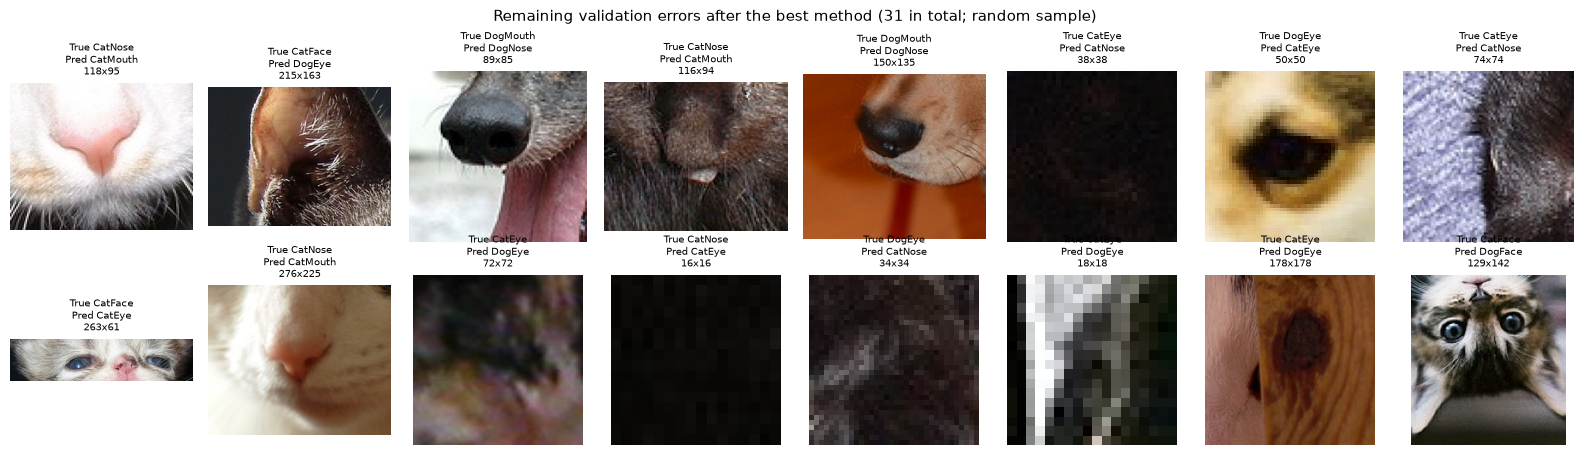

Most common remaining errors:


true      pred    
CatNose   CatMouth    9
CatEye    DogEye      4
          CatNose     3
CatFace   DogFace     3
DogEye    CatEye      2
DogMouth  DogNose     2
dtype: int64

In [26]:
wrong = val_df[best_val != y_val].assign(true=true_c[best_val != y_val], pred=names[best_val[best_val != y_val]])
sample = wrong.sample(min(16, len(wrong)), random_state=pp.SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, r) in zip(axes.flat, sample.iterrows()):
    with Image.open(pp.PROJECT_ROOT / r["path"]) as img:
        ax.imshow(img.convert("RGB"))
        ax.set_title(f"True {r['true']}\nPred {r['pred']}\n{img.width}x{img.height}", fontsize=7)
fig.suptitle(f"Remaining validation errors after the best method ({len(wrong)} in total; random sample)", fontsize=11)
plt.tight_layout(); fig.savefig(pp.FIG_DIR / "remaining_errors.png", dpi=150); plt.show()
print("Most common remaining errors:")
wrong.groupby(["true", "pred"]).size().sort_values(ascending=False).head(6)

### Summary of findings

**Where the errors are concentrated, and why.** \
\
The final model (fine-tuned ResNet-50) made 574 errors on the 12,686 validation images (95.48% accuracy). Of these, 535 (93.2%) were confusions between CatMouth and CatNose, and 96.5% of all errors identified the species correctly but the facial part wrongly. The other six classes all exceeded 99.2% recall. The cause is the centre-crop preprocessing: cat mouth crops are wide (median aspect ratio 1.42) and centred on the nose, so cropping them to a square removed the mouth corners and left content very similar to a nose crop. The original aspect ratio would have separated 99.6% of the confused images, and the original-versus-input figure shows the lost content directly. Some confusion also reflects label ambiguity, such as nose crops that include an open mouth.

**Validation versus Kaggle.** \
\
The first Kaggle submission scored 92.42%, 3.06 points below validation. Re-weighting validation accuracy to the test set's image-size mix lowered it by only 0.10 points, so image size explains very little of the gap. The gap also persisted after the CatMouth/CatNose fix (validation 99.76% versus Kaggle 95.84%), so it is not caused by that confusion. The most likely explanation is the source-photo leakage risk identified in Section 1.6: crops from the same animal fall in both training and validation, so validation partly measures recognition of familiar animals, while the test set measures generalisation to new ones.

**ResNet-50 versus the baseline.** \ 
\
On images where exactly one model was correct, ResNet-50 was right 254 times and the baseline 205 times. McNemar's test gives p = 0.025, so ResNet-50's 0.39-point advantage is statistically significant, but small relative to its 20 times larger parameter count.

**Improvement strategies (no retraining).** 
- Shape rule: fixed 535 errors on its own (95.48% to 99.69%), by far the largest effect.
- Ensemble of baseline and ResNet-50: fixed 52 errors on its own (p = 0.0001), since the two models make partly different mistakes.
- Test-time augmentation: no significant effect (p = 0.26), because horizontal flipping was already used in training, so the model's predictions were already flip-invariant.
- All three combined gave the highest validation accuracy (99.76%, 31 errors) and were submitted once, raising the Kaggle score from 92.42% to 95.84% (+3.42 points). The shape rule alone performed almost identically (8 more validation errors), at much lower cost.

**Remaining limitations and further improvements.** \
\
The 31 remaining validation errors are mostly near-empty, very small, oddly cropped, upside-down or apparently mislabelled images. The main limitation is the validation-to-test gap of about 3.9 points, which means validation can no longer guide further improvements. Recommended next steps:
- A group-aware validation split that keeps crops of the same animal together, for example by clustering visually similar images, so validation reflects performance on unseen animals.
- Stretch or padding preprocessing instead of centre-cropping, so the model learns crop shape and mouth content directly rather than through a post-hoc rule.
- Stronger pretrained backbones (for example ConvNeXt or EfficientNetV2), higher input resolution and larger ensembles, to improve generalisation to new animals.
- Stronger regularisation, retraining on all labelled data, vertical-flip augmentation and label cleaning.